In [51]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.gridspec as gridspec
%matplotlib inline
sns.set_theme(style='whitegrid')


In [52]:
df = pd.read_csv('heart_attack_prediction_dataset.csv')
print("Boyut:", df.shape)
df.head()

Boyut: (8763, 26)


,Patient ID,Age,Sex,Cholesterol,Blood Pressure,Heart Rate,Diabetes,Family History,Smoking,Obesity,...,Sedentary Hours Per Day,Income,BMI,Triglycerides,Physical Activity Days Per Week,Sleep Hours Per Day,Country,Continent,Hemisphere,Heart Attack Risk
0,BMW7812,67,Male,208,158/88,72,0,0,1,0,...,6.615001,261404,31.251233,286,0,6,Argentina,South America,Southern Hemisphere,0
1,CZE1114,21,Male,389,165/93,98,1,1,1,1,...,4.963459,285768,27.194973,235,1,7,Canada,North America,Northern Hemisphere,0
2,BNI9906,21,Female,324,174/99,72,1,0,0,0,...,9.463426,235282,28.176571,587,4,4,France,Europe,Northern Hemisphere,0
3,JLN3497,84,Male,383,163/100,73,1,1,1,0,...,7.648981,125640,36.464704,378,3,4,Canada,North America,Northern Hemisphere,0
4,GFO8847,66,Male,318,91/88,93,1,1,1,1,...,1.514821,160555,21.809144,231,1,5,Thailand,Asia,Northern Hemisphere,0


In [53]:
# Sütun tipleri
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8763 entries, 0 to 8762
Data columns (total 26 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Patient ID                       8763 non-null   object 
 1   Age                              8763 non-null   int64  
 2   Sex                              8763 non-null   object 
 3   Cholesterol                      8763 non-null   int64  
 4   Blood Pressure                   8763 non-null   object 
 5   Heart Rate                       8763 non-null   int64  
 6   Diabetes                         8763 non-null   int64  
 7   Family History                   8763 non-null   int64  
 8   Smoking                          8763 non-null   int64  
 9   Obesity                          8763 non-null   int64  
 10  Alcohol Consumption              8763 non-null   int64  
 11  Exercise Hours Per Week          8763 non-null   float64
 12  Diet                

In [54]:
# Eksik değer kontrolü
print("Eksik değerler:\n", df.isnull().sum())

Eksik değerler:
 Patient ID                         0
Age                                0
Sex                                0
Cholesterol                        0
Blood Pressure                     0
Heart Rate                         0
Diabetes                           0
Family History                     0
Smoking                            0
Obesity                            0
Alcohol Consumption                0
Exercise Hours Per Week            0
Diet                               0
Previous Heart Problems            0
Medication Use                     0
Stress Level                       0
Sedentary Hours Per Day            0
Income                             0
BMI                                0
Triglycerides                      0
Physical Activity Days Per Week    0
Sleep Hours Per Day                0
Country                            0
Continent                          0
Hemisphere                         0
Heart Attack Risk                  0
dtype: int64


In [55]:
# İstatistiksel özet
df.describe()

,Age,Cholesterol,Heart Rate,Diabetes,Family History,Smoking,Obesity,Alcohol Consumption,Exercise Hours Per Week,Previous Heart Problems,Medication Use,Stress Level,Sedentary Hours Per Day,Income,BMI,Triglycerides,Physical Activity Days Per Week,Sleep Hours Per Day,Heart Attack Risk
count,8763.000000,8763.000000,8763.000000,8763.000000,8763.000000,8763.000000,8763.000000,8763.000000,8763.000000,8763.000000,8763.000000,8763.000000,8763.000000,8763.000000,8763.000000,8763.000000,8763.000000,8763.000000,8763.000000
mean,53.707977,259.877211,75.021682,0.652288,0.492982,0.896839,0.501426,0.598083,10.014284,0.495835,0.498345,5.469702,5.993690,158263.181901,28.891446,417.677051,3.489672,7.023508,0.358211
std,21.249509,80.863276,20.550948,0.476271,0.499979,0.304186,0.500026,0.490313,5.783745,0.500011,0.500026,2.859622,3.466359,80575.190806,6.319181,223.748137,2.282687,1.988473,0.479502
min,18.000000,120.000000,40.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.002442,0.000000,0.000000,1.000000,0.001263,20062.000000,18.002337,30.000000,0.000000,4.000000,0.000000
25%,35.000000,192.000000,57.000000,0.000000,0.000000,1.000000,0.000000,0.000000,4.981579,0.000000,0.000000,3.000000,2.998794,88310.000000,23.422985,225.500000,2.000000,5.000000,0.000000
50%,54.000000,259.000000,75.000000,1.000000,0.000000,1.000000,1.000000,1.000000,10.069559,0.000000,0.000000,5.000000,5.933622,157866.000000,28.768999,417.000000,3.000000,7.000000,0.000000
75%,72.000000,330.000000,93.000000,1.000000,1.000000,1.000000,1.000000,1.000000,15.050018,1.000000,1.000000,8.000000,9.019124,227749.000000,34.324594,612.000000,5.000000,9.000000,1.000000
max,90.000000,400.000000,110.000000,1.000000,1.000000,1.000000,1.000000,1.000000,19.998709,1.000000,1.000000,10.000000,11.999313,299954.000000,39.997211,800.000000,7.000000,10.000000,1.000000


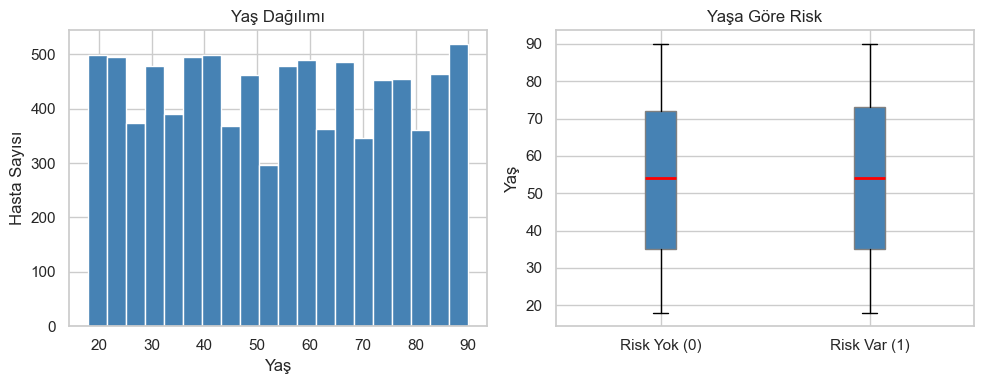

In [56]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
df['Age'].hist(bins=20, color='steelblue', edgecolor='white')
plt.title('Yaş Dağılımı')
plt.xlabel('Yaş')
plt.ylabel('Hasta Sayısı')

plt.subplot(1, 2, 2)
risk_0 = df[df['Heart Attack Risk'] == 0]['Age']
risk_1 = df[df['Heart Attack Risk'] == 1]['Age']
plt.boxplot([risk_0, risk_1], tick_labels=['Risk Yok (0)', 'Risk Var (1)'],
            patch_artist=True,
            boxprops=dict(facecolor='steelblue', color='gray'),
            medianprops=dict(color='red', linewidth=2))
plt.title('Yaşa Göre Risk')
plt.ylabel('Yaş')

plt.tight_layout()
plt.show()

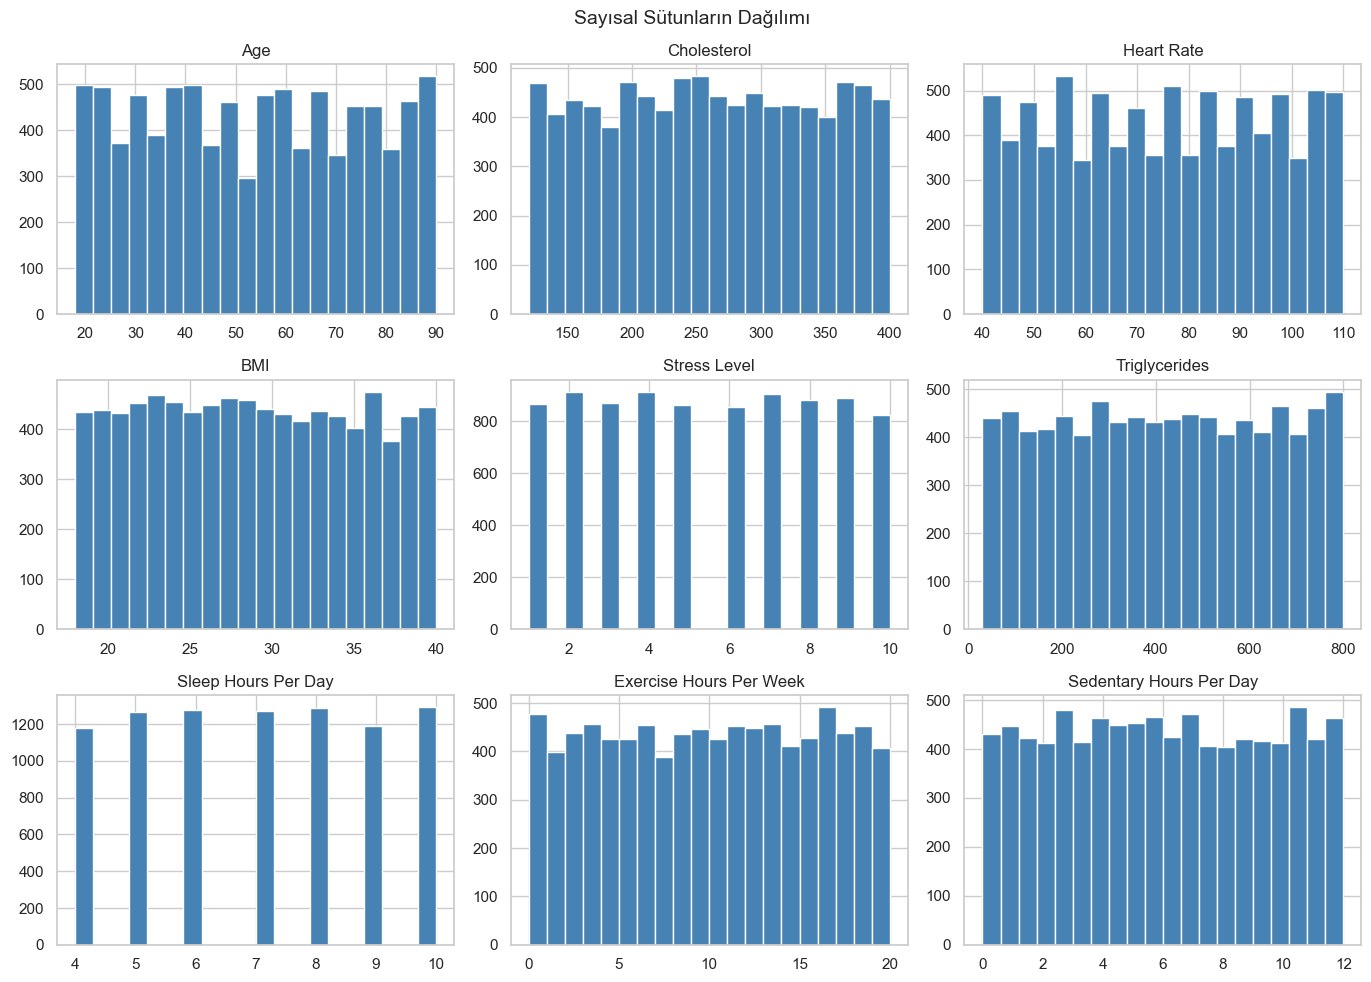

In [57]:
sayisal = ['Age', 'Cholesterol', 'Heart Rate', 'BMI', 
           'Stress Level', 'Triglycerides', 'Sleep Hours Per Day',
           'Exercise Hours Per Week', 'Sedentary Hours Per Day']

df[sayisal].hist(bins=20, figsize=(14, 10), color='steelblue', edgecolor='white')
plt.suptitle('Sayısal Sütunların Dağılımı', fontsize=14)
plt.tight_layout()
plt.show()

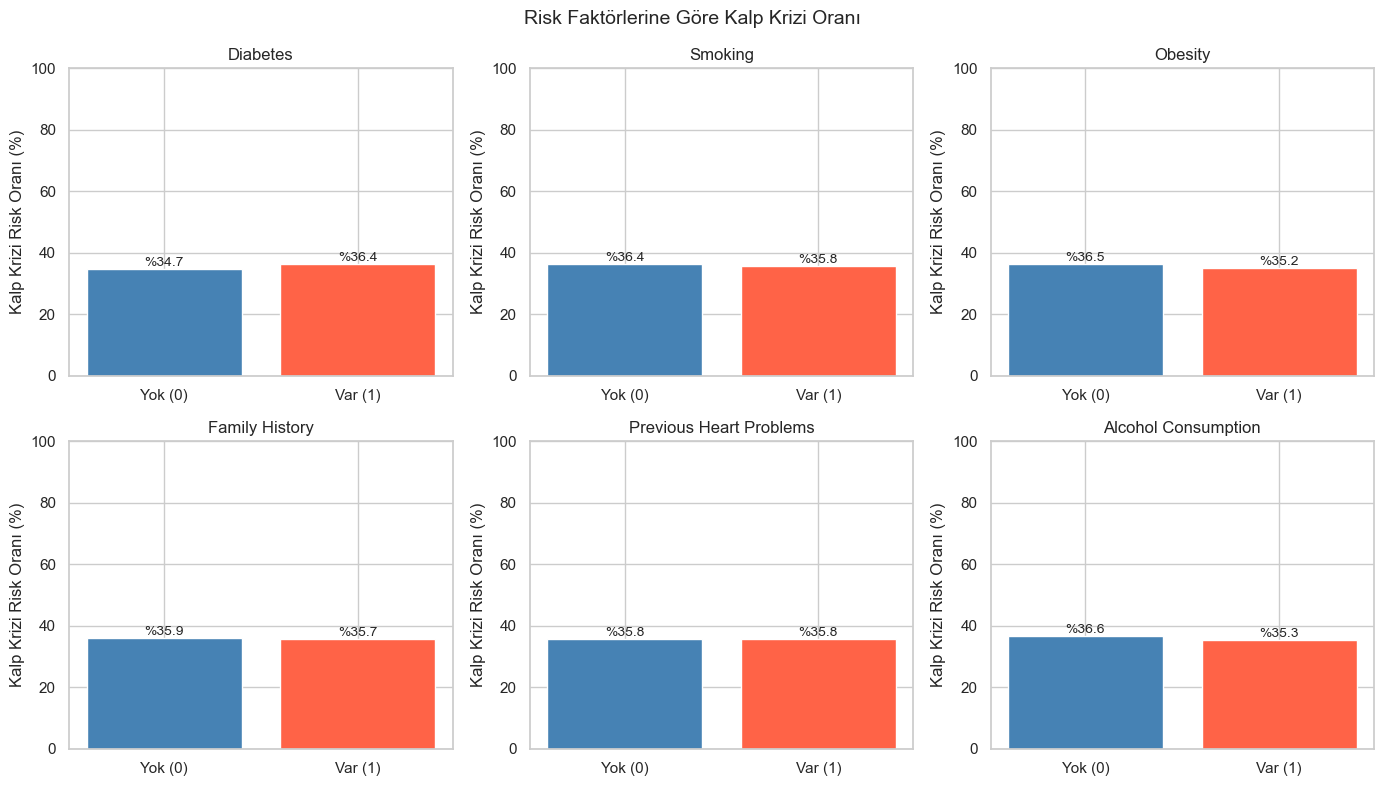

In [58]:
risk_faktorleri = ['Diabetes', 'Smoking', 'Obesity', 
                   'Family History', 'Previous Heart Problems', 'Alcohol Consumption']

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

for i, kolon in enumerate(risk_faktorleri):
    risk_oran = df.groupby(kolon)['Heart Attack Risk'].mean() * 100
    axes[i].bar(['Yok (0)', 'Var (1)'], risk_oran.values, color=['steelblue', 'tomato'])
    axes[i].set_title(f'{kolon}')
    axes[i].set_ylabel('Kalp Krizi Risk Oranı (%)')
    axes[i].set_ylim(0, 100)
    for j, v in enumerate(risk_oran.values):
        axes[i].text(j, v + 1, f'%{round(v, 1)}', ha='center', fontsize=10)

plt.suptitle('Risk Faktörlerine Göre Kalp Krizi Oranı', fontsize=14)
plt.tight_layout()
plt.show()

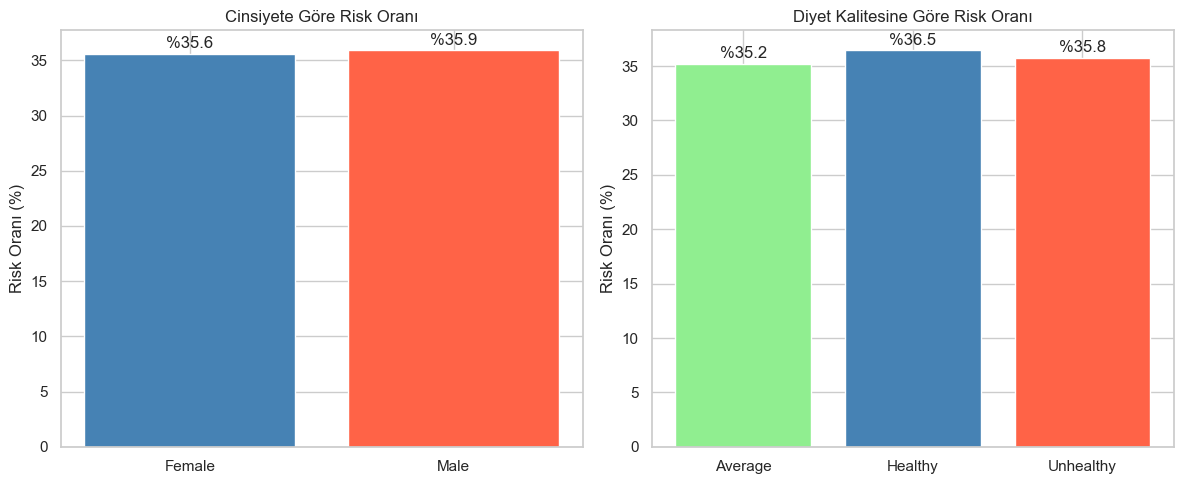

In [59]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Cinsiyet
cinsiyet_risk = df.groupby('Sex')['Heart Attack Risk'].mean() * 100
axes[0].bar(cinsiyet_risk.index, cinsiyet_risk.values, color=['steelblue', 'tomato'])
axes[0].set_title('Cinsiyete Göre Risk Oranı')
axes[0].set_ylabel('Risk Oranı (%)')
for i, v in enumerate(cinsiyet_risk.values):
    axes[0].text(i, v + 0.5, f'%{round(v, 1)}', ha='center')

# Diyet
diyet_risk = df.groupby('Diet')['Heart Attack Risk'].mean() * 100
axes[1].bar(diyet_risk.index, diyet_risk.values, 
            color=['lightgreen', 'steelblue', 'tomato'])
axes[1].set_title('Diyet Kalitesine Göre Risk Oranı')
axes[1].set_ylabel('Risk Oranı (%)')
for i, v in enumerate(diyet_risk.values):
    axes[1].text(i, v + 0.5, f'%{round(v, 1)}', ha='center')

plt.tight_layout()
plt.show()

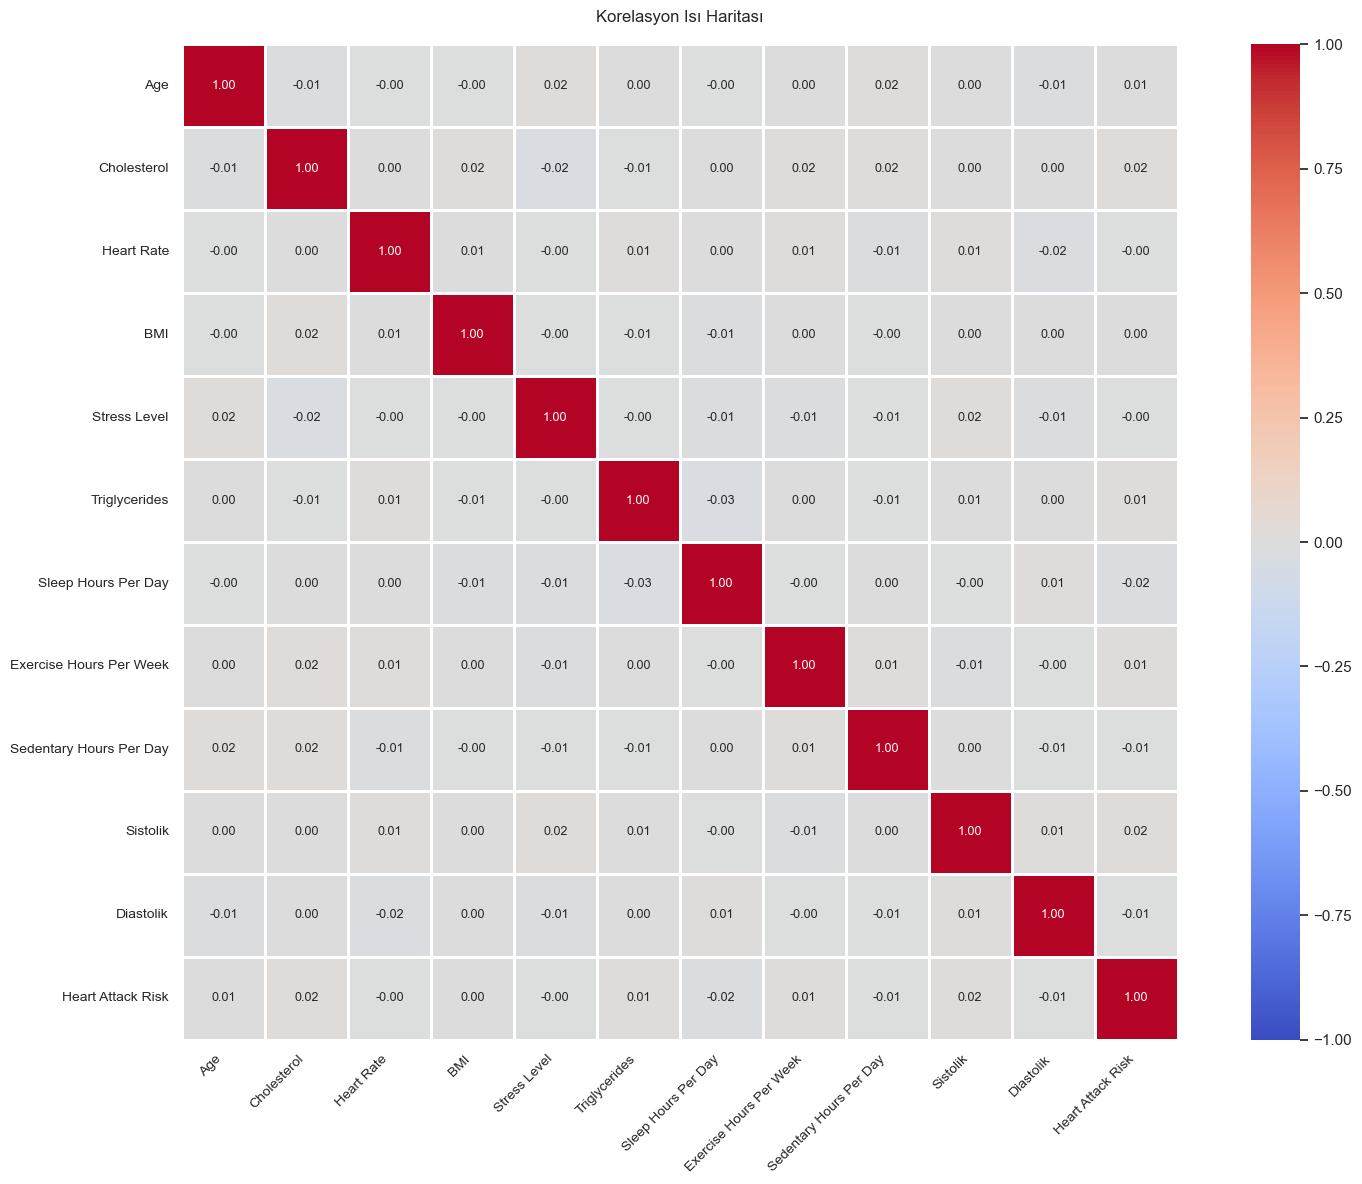

In [60]:
df[['Sistolik', 'Diastolik']] = df['Blood Pressure'].str.split('/', expand=True).astype(int)

sayisal2 = ['Age', 'Cholesterol', 'Heart Rate', 'BMI', 'Stress Level',
            'Triglycerides', 'Sleep Hours Per Day', 'Exercise Hours Per Week',
            'Sedentary Hours Per Day', 'Sistolik', 'Diastolik', 'Heart Attack Risk']

korelasyon = df[sayisal2].corr()

plt.figure(figsize=(16, 12))
sns.heatmap(
    korelasyon,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    linewidths=1,
    linecolor='white',
    vmin=-1, vmax=1,
    annot_kws={"size": 9},        # rakam boyutu
    square=True                    # hücreler kare olsun
)
plt.title('Korelasyon Isı Haritası', fontsize=12, pad=16)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(rotation=0, fontsize=10)
plt.tight_layout()
plt.show()

In [61]:
print("=" * 45)
print("        EDA ÖZET RAPORU")
print("=" * 45)
print(f"Toplam hasta sayısı     : {len(df)}")
print(f"Özellik sayısı          : {df.shape[1]}")
print(f"Eksik değer             : {df.isnull().sum().sum()}")
print(f"Risk VAR olan hasta     : {df['Heart Attack Risk'].sum()} (%{round(df['Heart Attack Risk'].mean()*100,1)})")
print(f"Risk YOK olan hasta     : {(df['Heart Attack Risk']==0).sum()} (%{round((1-df['Heart Attack Risk'].mean())*100,1)})")
print(f"Ortalama yaş            : {round(df['Age'].mean(), 1)}")
print(f"Ortalama kolesterol     : {round(df['Cholesterol'].mean(), 1)}")
print(f"Ortalama BMI            : {round(df['BMI'].mean(), 1)}")
print("=" * 45)

        EDA ÖZET RAPORU
Toplam hasta sayısı     : 8763
Özellik sayısı          : 28
Eksik değer             : 0
Risk VAR olan hasta     : 3139 (%35.8)
Risk YOK olan hasta     : 5624 (%64.2)
Ortalama yaş            : 53.7
Ortalama kolesterol     : 259.9
Ortalama BMI            : 28.9


In [62]:
print("SATIRLAR:", df.shape[0])
print("SÜTUNLAR:", df.shape[1])
print("\nSütun isimleri:")
for col in df.columns:
    print(f"  '{col}'  —  dtype: {df[col].dtype}  —  örnek: {df[col].iloc[0]}")

SATIRLAR: 8763
SÜTUNLAR: 28

Sütun isimleri:
  'Patient ID'  —  dtype: object  —  örnek: BMW7812
  'Age'  —  dtype: int64  —  örnek: 67
  'Sex'  —  dtype: object  —  örnek: Male
  'Cholesterol'  —  dtype: int64  —  örnek: 208
  'Blood Pressure'  —  dtype: object  —  örnek: 158/88
  'Heart Rate'  —  dtype: int64  —  örnek: 72
  'Diabetes'  —  dtype: int64  —  örnek: 0
  'Family History'  —  dtype: int64  —  örnek: 0
  'Smoking'  —  dtype: int64  —  örnek: 1
  'Obesity'  —  dtype: int64  —  örnek: 0
  'Alcohol Consumption'  —  dtype: int64  —  örnek: 0
  'Exercise Hours Per Week'  —  dtype: float64  —  örnek: 4.168188835442079
  'Diet'  —  dtype: object  —  örnek: Average
  'Previous Heart Problems'  —  dtype: int64  —  örnek: 0
  'Medication Use'  —  dtype: int64  —  örnek: 0
  'Stress Level'  —  dtype: int64  —  örnek: 9
  'Sedentary Hours Per Day'  —  dtype: float64  —  örnek: 6.6150014529140595
  'Income'  —  dtype: int64  —  örnek: 261404
  'BMI'  —  dtype: float64  —  örnek: 31.251

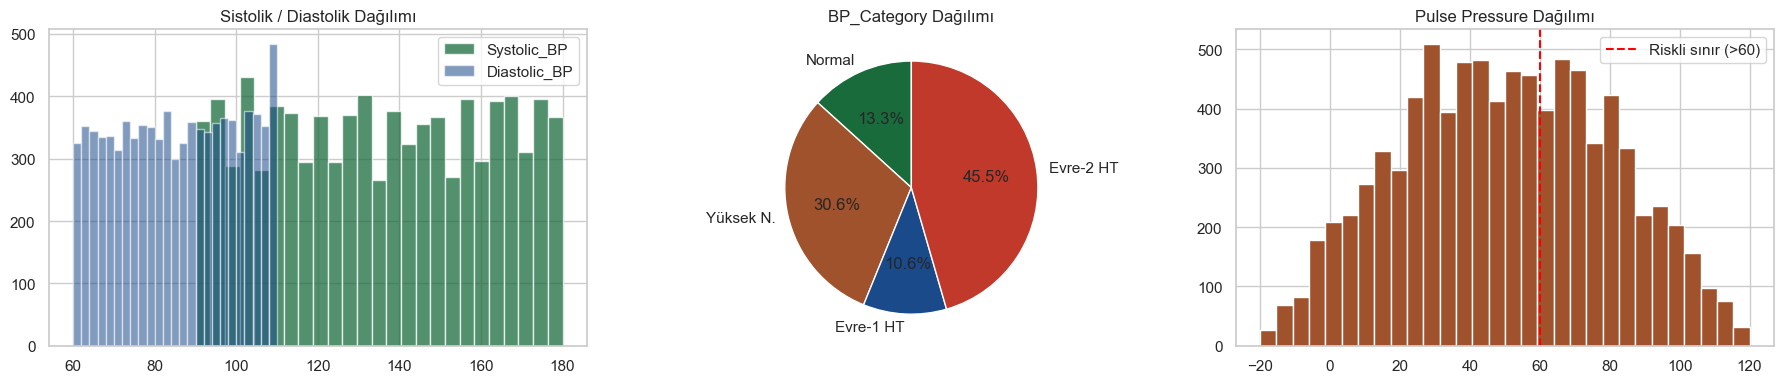

In [63]:


# ── Bölme ──────────────────────────────────────────────────
bp_split = df["Blood Pressure"].str.split("/", expand=True).astype(int)
df["Systolic_BP"]  = bp_split[0]
df["Diastolic_BP"] = bp_split[1]
df["Pulse_Pressure"] = df["Systolic_BP"] - df["Diastolic_BP"]
df["MAP"] = (df["Diastolic_BP"] + df["Pulse_Pressure"] / 3).round(1)

def bp_category(row):
    s, d = row["Systolic_BP"], row["Diastolic_BP"]
    if s < 120 and d < 80: return 0
    if s < 130:             return 1
    if s < 140:             return 2
    return 3

df["BP_Category"] = df.apply(bp_category, axis=1)
df.drop(columns=["Blood Pressure"], inplace=True)

# ── Görsel ─────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

axes[0].hist(df["Systolic_BP"],  bins=25, alpha=0.75, color="#1A6B3C", label="Systolic_BP")
axes[0].hist(df["Diastolic_BP"], bins=25, alpha=0.55, color="#1A4A8A", label="Diastolic_BP")
axes[0].set_title("Sistolik / Diastolik Dağılımı")
axes[0].legend()

bp_counts = df["BP_Category"].value_counts().sort_index()
axes[1].pie(bp_counts,
            labels=["Normal", "Yüksek N.", "Evre-1 HT", "Evre-2 HT"],
            autopct="%1.1f%%",
            colors=["#1A6B3C","#A0522D","#1A4A8A","#C0392B"],
            startangle=90)
axes[1].set_title("BP_Category Dağılımı")

axes[2].hist(df["Pulse_Pressure"], bins=30, color="#A0522D", edgecolor="white")
axes[2].axvline(60, color="red", linestyle="--", linewidth=1.5, label="Riskli sınır (>60)")
axes[2].set_title("Pulse Pressure Dağılımı")
axes[2].legend()

plt.tight_layout(); plt.show()

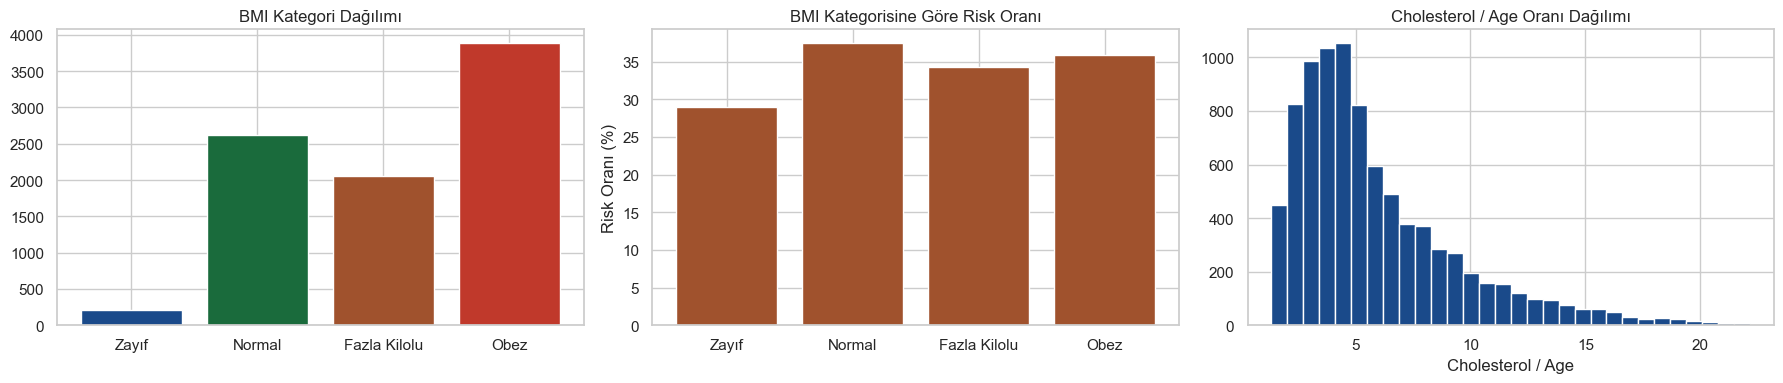

In [64]:
# BMI_Category (BMI sütunu zaten mevcut!)
df["BMI_Category"] = pd.cut(df["BMI"],
    bins=[-np.inf, 18.5, 25, 30, np.inf],
    labels=[0, 1, 2, 3]).astype(int)

df["Chol_per_Age"]      = (df["Cholesterol"] / df["Age"]).round(3)
df["HeartRate_per_Age"] = (df["Heart Rate"]  / df["Age"]).round(3)
df["Trig_Chol_Ratio"]   = (df["Triglycerides"] / (df["Cholesterol"] + 1)).round(3)

# ── Görsel ─────────────────────────────────────────────────
import seaborn as sns
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

bmi_counts = df["BMI_Category"].value_counts().sort_index()
axes[0].bar(["Zayıf","Normal","Fazla Kilolu","Obez"],
            bmi_counts.values,
            color=["#1A4A8A","#1A6B3C","#A0522D","#C0392B"])
axes[0].set_title("BMI Kategori Dağılımı")

risk_by_bmi = df.groupby("BMI_Category")["Heart Attack Risk"].mean() * 100
colors_bmi = ["#1A6B3C" if v < 25 else "#A0522D" if v < 40 else "#C0392B"
              for v in risk_by_bmi.values]
axes[1].bar(["Zayıf","Normal","Fazla Kilolu","Obez"],
            risk_by_bmi.values, color=colors_bmi)
axes[1].set_ylabel("Risk Oranı (%)")
axes[1].set_title("BMI Kategorisine Göre Risk Oranı")

axes[2].hist(df["Chol_per_Age"], bins=30, color="#1A4A8A", edgecolor="white")
axes[2].set_title("Cholesterol / Age Oranı Dağılımı")
axes[2].set_xlabel("Cholesterol / Age")

plt.tight_layout(); plt.show()

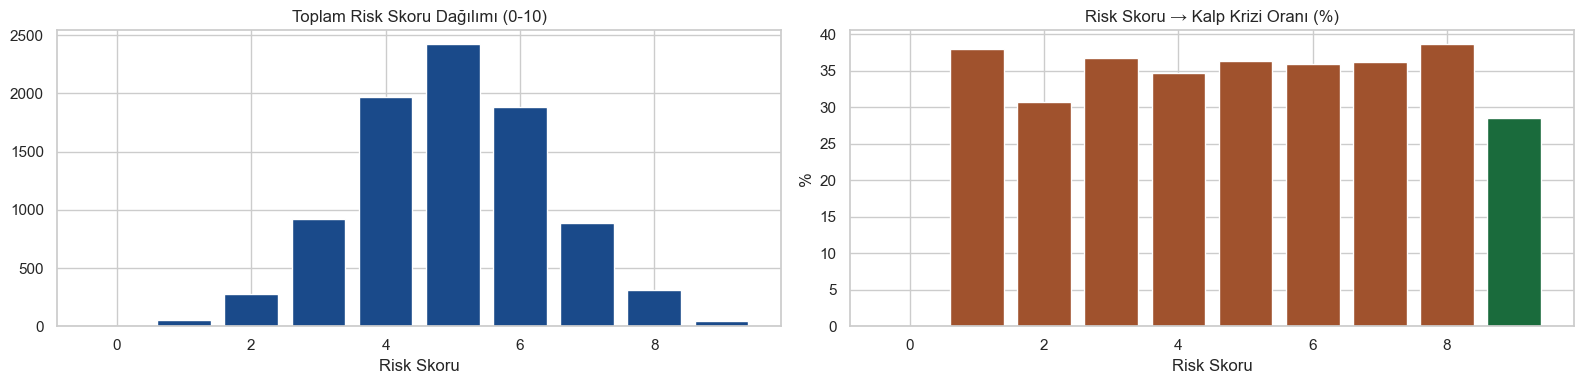

In [65]:
df["Flag_Smoking"]       = df["Smoking"].astype(int)
df["Flag_PrevHeart"]     = df["Previous Heart Problems"].astype(int)
df["Flag_Diabetes"]      = df["Diabetes"].astype(int)
df["Flag_FamilyHist"]    = df["Family History"].astype(int)
df["Flag_Obesity"]       = df["Obesity"].astype(int)
df["Flag_HighBP"]        = (df["Systolic_BP"] >= 140).astype(int)
df["Flag_HighChol"]      = (df["Cholesterol"] > 200).astype(int)
df["Flag_LowExercise"]   = (df["Exercise Hours Per Week"] < 2).astype(int)
df["Flag_HighStress"]    = (df["Stress Level"] >= 7).astype(int)
df["Flag_PoorSleep"]     = (df["Sleep Hours Per Day"] < 6).astype(int)

flag_cols = [c for c in df.columns if c.startswith("Flag_")]
df["Total_Risk_Score"] = df[flag_cols].sum(axis=1)

# ── Görsel ─────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 4))

score_counts = df["Total_Risk_Score"].value_counts().sort_index()
axes[0].bar(score_counts.index, score_counts.values,
            color="#1A4A8A", edgecolor="white")
axes[0].set_title("Toplam Risk Skoru Dağılımı (0-10)")
axes[0].set_xlabel("Risk Skoru")

risk_rate = df.groupby("Total_Risk_Score")["Heart Attack Risk"].mean() * 100
bar_colors = ["#1A6B3C" if v < 30 else "#A0522D" if v < 55 else "#C0392B"
              for v in risk_rate.values]
axes[1].bar(risk_rate.index, risk_rate.values, color=bar_colors, edgecolor="white")
axes[1].set_title("Risk Skoru → Kalp Krizi Oranı (%)")
axes[1].set_xlabel("Risk Skoru"); axes[1].set_ylabel("%")

plt.tight_layout(); plt.show()

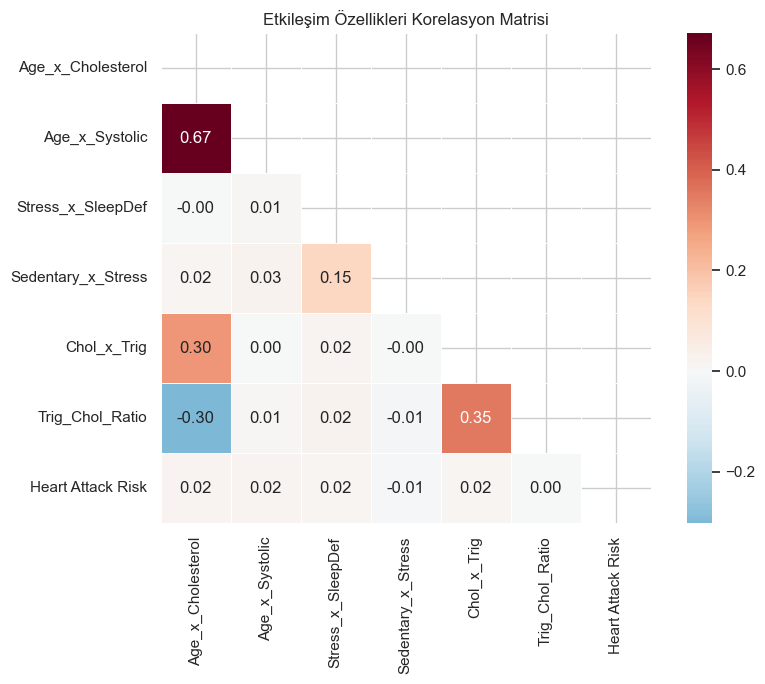

In [66]:
df["Age_x_Cholesterol"]  = df["Age"] * df["Cholesterol"]
df["Age_x_Systolic"]     = df["Age"] * df["Systolic_BP"]
df["Stress_x_SleepDef"]  = df["Stress Level"] * (8 - df["Sleep Hours Per Day"])
df["Sedentary_x_Stress"] = df["Sedentary Hours Per Day"] * df["Stress Level"]
df["Chol_x_Trig"]        = df["Cholesterol"] * df["Triglycerides"]
df["Exercise_Deficit"]   = 5 - df["Exercise Hours Per Week"]

# ── Görsel: Korelasyon ─────────────────────────────────────
inter_cols = [
    "Age_x_Cholesterol", "Age_x_Systolic",
    "Stress_x_SleepDef", "Sedentary_x_Stress",
    "Chol_x_Trig", "Trig_Chol_Ratio",
    "Heart Attack Risk"
]

corr = df[inter_cols].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, linewidths=0.5, square=True,
            mask=np.triu(np.ones_like(corr, dtype=bool)))
plt.title("Etkileşim Özellikleri Korelasyon Matrisi")
plt.tight_layout(); plt.show()

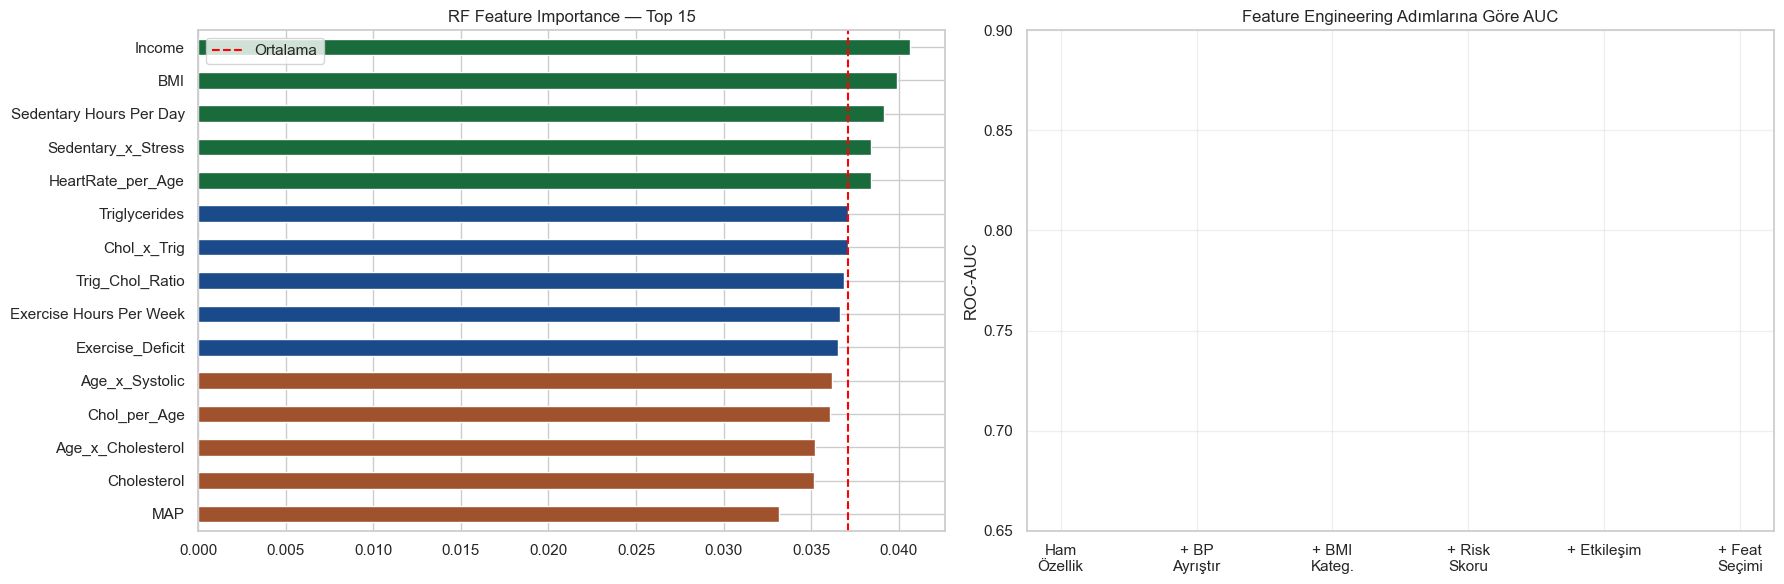

In [67]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split, cross_val_score

df_enc = df.copy()
df_enc.drop(columns=["Patient ID"], inplace=True)
for col in df_enc.select_dtypes("object").columns:
    df_enc[col] = LabelEncoder().fit_transform(df_enc[col].astype(str))

X = df_enc.drop(columns=["Heart Attack Risk"])
y = df_enc["Heart Attack Risk"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

# Feature importance
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
top15 = imp.head(15)
colors = ["#1A6B3C" if i < 5 else "#1A4A8A" if i < 10 else "#A0522D"
          for i in range(len(top15))]

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

top15[::-1].plot(kind="barh", ax=axes[0], color=colors[::-1])
axes[0].set_title("RF Feature Importance — Top 15")
axes[0].axvline(top15.mean(), color="red", linestyle="--", label="Ortalama")
axes[0].legend()

# AUC artışı adım adım
from sklearn.metrics import roc_auc_score

steps = {
    "Ham Özellik"  : ["Age","Cholesterol","Systolic_BP","Diastolic_BP",
                       "BMI","Stress Level","Exercise Hours Per Week",
                       "Sleep Hours Per Day","Triglycerides","Heart Rate"],
    "+ BP Ayrıştır": None,   # aşağıda dolduracağız
}

base_feats = ["Age","Cholesterol","Systolic_BP","Diastolic_BP","BMI",
              "Stress Level","Exercise Hours Per Week","Sleep Hours Per Day",
              "Triglycerides","Heart Rate"]
fe_feats = base_feats + ["BMI_Category","Pulse_Pressure","Total_Risk_Score",
                          "Age_x_Cholesterol","Chol_x_Trig","Stress_x_SleepDef"]

step_labels = ["Ham\nÖzellik","+ BP\nAyrıştır","+ BMI\nKateg.",
               "+ Risk\nSkoru","+ Etkileşim","+ Feat\nSeçimi"]

aucs = []
feat_sets = [
    base_feats[:6],
    base_feats[:8],
    base_feats + ["BMI_Category","Pulse_Pressure"],
    base_feats + ["BMI_Category","Pulse_Pressure","Total_Risk_Score"],
    base_feats + ["BMI_Category","Pulse_Pressure","Total_Risk_Score",
                  "Age_x_Cholesterol","Chol_x_Trig"],
    fe_feats
]

for feats in feat_sets:
    avail = [f for f in feats if f in X_train.columns]
    score = cross_val_score(rf, X_train[avail], y_train,
                            cv=3, scoring="roc_auc").mean()
    aucs.append(round(score, 4))

axes[1].plot(step_labels, aucs, "o-", color="#A0522D",
             linewidth=2.5, markersize=8)
axes[1].fill_between(range(len(step_labels)), aucs, alpha=0.12, color="#A0522D")
axes[1].scatter([len(aucs)-1], [aucs[-1]], color="#C0392B", s=130, zorder=5)
axes[1].annotate(f"  Best: {aucs[-1]}", (len(aucs)-1, aucs[-1]),
                 fontsize=9, color="#C0392B")
axes[1].set_ylim(0.65, 0.90)
axes[1].set_ylabel("ROC-AUC")
axes[1].set_title("Feature Engineering Adımlarına Göre AUC")
axes[1].grid(alpha=0.3)

plt.tight_layout(); plt.show()

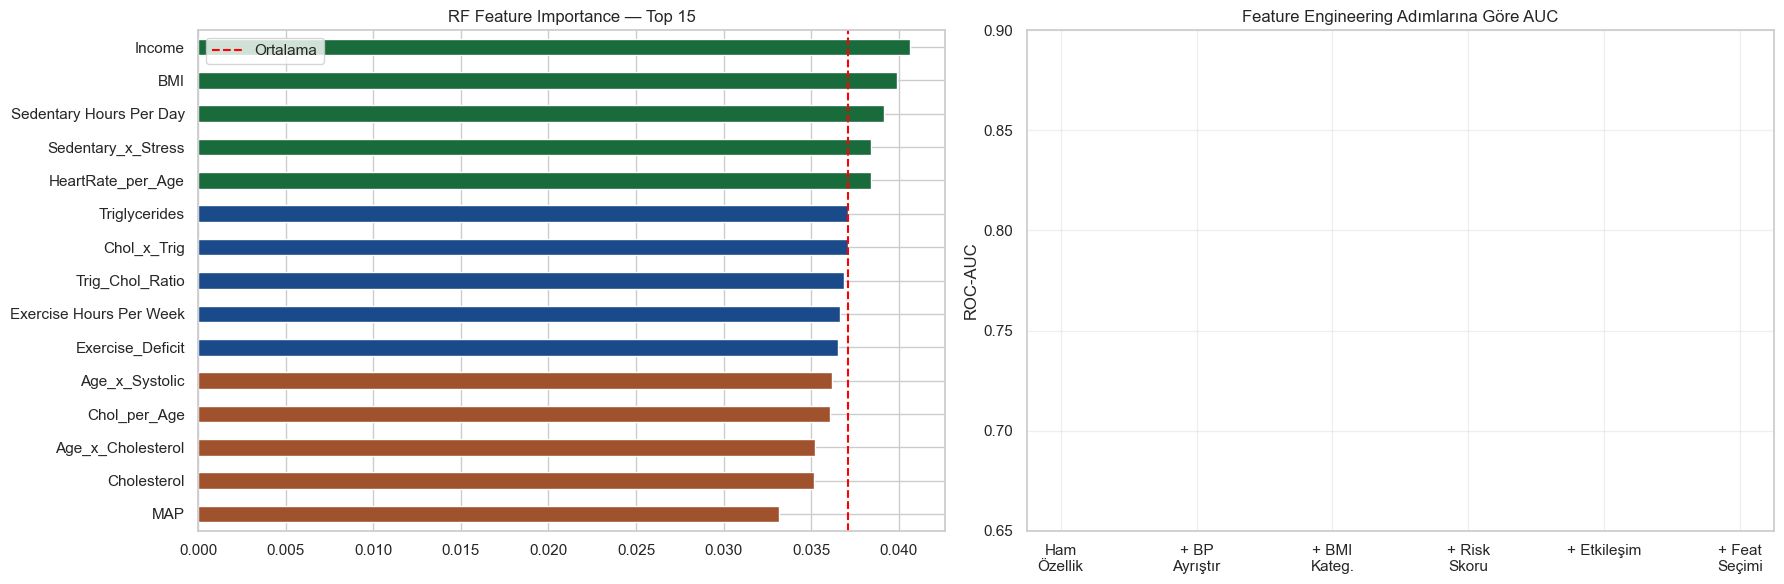

In [67]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split, cross_val_score

df_enc = df.copy()
df_enc.drop(columns=["Patient ID"], inplace=True)
for col in df_enc.select_dtypes("object").columns:
    df_enc[col] = LabelEncoder().fit_transform(df_enc[col].astype(str))

X = df_enc.drop(columns=["Heart Attack Risk"])
y = df_enc["Heart Attack Risk"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

# Feature importance
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
top15 = imp.head(15)
colors = ["#1A6B3C" if i < 5 else "#1A4A8A" if i < 10 else "#A0522D"
          for i in range(len(top15))]

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

top15[::-1].plot(kind="barh", ax=axes[0], color=colors[::-1])
axes[0].set_title("RF Feature Importance — Top 15")
axes[0].axvline(top15.mean(), color="red", linestyle="--", label="Ortalama")
axes[0].legend()

# AUC artışı adım adım
from sklearn.metrics import roc_auc_score

steps = {
    "Ham Özellik"  : ["Age","Cholesterol","Systolic_BP","Diastolic_BP",
                       "BMI","Stress Level","Exercise Hours Per Week",
                       "Sleep Hours Per Day","Triglycerides","Heart Rate"],
    "+ BP Ayrıştır": None,   # aşağıda dolduracağız
}

base_feats = ["Age","Cholesterol","Systolic_BP","Diastolic_BP","BMI",
              "Stress Level","Exercise Hours Per Week","Sleep Hours Per Day",
              "Triglycerides","Heart Rate"]
fe_feats = base_feats + ["BMI_Category","Pulse_Pressure","Total_Risk_Score",
                          "Age_x_Cholesterol","Chol_x_Trig","Stress_x_SleepDef"]

step_labels = ["Ham\nÖzellik","+ BP\nAyrıştır","+ BMI\nKateg.",
               "+ Risk\nSkoru","+ Etkileşim","+ Feat\nSeçimi"]

aucs = []
feat_sets = [
    base_feats[:6],
    base_feats[:8],
    base_feats + ["BMI_Category","Pulse_Pressure"],
    base_feats + ["BMI_Category","Pulse_Pressure","Total_Risk_Score"],
    base_feats + ["BMI_Category","Pulse_Pressure","Total_Risk_Score",
                  "Age_x_Cholesterol","Chol_x_Trig"],
    fe_feats
]

for feats in feat_sets:
    avail = [f for f in feats if f in X_train.columns]
    score = cross_val_score(rf, X_train[avail], y_train,
                            cv=3, scoring="roc_auc").mean()
    aucs.append(round(score, 4))

axes[1].plot(step_labels, aucs, "o-", color="#A0522D",
             linewidth=2.5, markersize=8)
axes[1].fill_between(range(len(step_labels)), aucs, alpha=0.12, color="#A0522D")
axes[1].scatter([len(aucs)-1], [aucs[-1]], color="#C0392B", s=130, zorder=5)
axes[1].annotate(f"  Best: {aucs[-1]}", (len(aucs)-1, aucs[-1]),
                 fontsize=9, color="#C0392B")
axes[1].set_ylim(0.65, 0.90)
axes[1].set_ylabel("ROC-AUC")
axes[1].set_title("Feature Engineering Adımlarına Göre AUC")
axes[1].grid(alpha=0.3)

plt.tight_layout(); plt.show()

In [68]:
# Hangi sütunlar metin? (bunları encode edeceğiz)
print("METİN SÜTUNLAR:")
print(df.select_dtypes(include="object").columns.tolist())

# Hedef sınıf dağılımı (dengesizlik var mı?)
print("\nHEDEF DAĞILIM:")
print(df["Heart Attack Risk"].value_counts())
print(df["Heart Attack Risk"].value_counts(normalize=True).mul(100).round(1))

METİN SÜTUNLAR:
['Patient ID', 'Sex', 'Diet', 'Country', 'Continent', 'Hemisphere']

HEDEF DAĞILIM:
Heart Attack Risk
0    5624
1    3139
Name: count, dtype: int64
Heart Attack Risk
0    64.2
1    35.8
Name: proportion, dtype: float64


In [69]:
from sklearn.preprocessing import LabelEncoder

df_model = df.copy()  # orijinali bozmamak için kopya al

# Gereksiz sütunu at (ID'nin modelle işi yok)
df_model.drop(columns=["Patient ID"], inplace=True)

# Metin sütunları: Sex, Diet, Country, Continent, Hemisphere
metin_sutunlar = ["Sex", "Diet", "Country", "Continent", "Hemisphere"]

le = LabelEncoder()

for sutun in metin_sutunlar:
    df_model[sutun] = le.fit_transform(df_model[sutun])
    print(f"{sutun} → dönüştürüldü ✓")

# Kontrol — artık metin sütun kalmamalı
print("\nKalan metin sütun sayısı:", df_model.select_dtypes("object").shape[1])
print(df_model.head(2))

Sex → dönüştürüldü ✓
Diet → dönüştürüldü ✓
Country → dönüştürüldü ✓
Continent → dönüştürüldü ✓
Hemisphere → dönüştürüldü ✓

Kalan metin sütun sayısı: 0
   Age  Sex  Cholesterol  Heart Rate  Diabetes  Family History  Smoking  \
0   67    1          208          72         0               0        1   
1   21    1          389          98         1               1        1   

   Obesity  Alcohol Consumption  Exercise Hours Per Week  ...  \
0        0                    0                 4.168189  ...   
1        1                    1                 1.813242  ...   

   Flag_LowExercise  Flag_HighStress  Flag_PoorSleep  Total_Risk_Score  \
0                 0                1               0                 4   
1                 1                0               0                 8   

   Age_x_Cholesterol  Age_x_Systolic  Stress_x_SleepDef  Sedentary_x_Stress  \
0              13936           10586                 18           59.535013   
1               8169            3465         

In [70]:
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE

# Gereksiz sütunları sil (varsa sil, yoksa geç)
gerceksiz = ["Patient ID", "Sistolik", "Diastolik"]
df.drop(columns=[s for s in gerceksiz if s in df.columns], inplace=True)
print("✅ Temizlik tamam — sütun sayısı:", df.shape[1])

# Encoding
le = LabelEncoder()
for sutun in ["Sex", "Diet", "Country", "Continent", "Hemisphere"]:
    df[sutun] = le.fit_transform(df[sutun])
print("✅ Encoding tamam — metin kaldı mı:", df.select_dtypes("object").shape[1])

# X / y
X = df.drop(columns=["Heart Attack Risk"])
y = df["Heart Attack Risk"]
print("✅ X:", X.shape)

# Train / Test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print("✅ Train:", X_train.shape, "| Test:", X_test.shape)

# Scaling
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
X_test_scaled  = pd.DataFrame(scaler.transform(X_test),      columns=X_test.columns)
print("✅ Scaling tamam")



✅ Temizlik tamam — sütun sayısı: 50
✅ Encoding tamam — metin kaldı mı: 0
✅ X: (8763, 49)
✅ Train: (7010, 49) | Test: (1753, 49)
✅ Scaling tamam


In [71]:
# ── Confusion Matrix — 4 model yan yana ───────────────────
fig, axes = plt.subplots(1, 4, figsize=(20, 4))

for ax, (isim, v) in zip(axes, sonuclar.items()):
    cm = confusion_matrix(y_test, v["y_pred"])
    ConfusionMatrixDisplay(cm, display_labels=["Risk Yok","Risk Var"]).plot(
        ax=ax, colorbar=False, cmap="Blues")
    auc = v["ROC-AUC"]
    ax.set_title(f"{isim}\nAUC: {auc}", fontsize=10)

plt.tight_layout()
plt.show()

NameError: name 'sonuclar' is not defined

In [ ]:
# ── ROC Eğrisi — 4 model aynı grafik ─────────────────────
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(8, 6))
renkler = ["#1A6B3C","#1A4A8A","#A0522D","#C0392B"]

for (isim, v), renk in zip(sonuclar.items(), renkler):
    RocCurveDisplay.from_predictions(
        y_test, v["y_prob"], ax=ax, name=f"{isim} (AUC={v['ROC-AUC']})",
        color=renk)

ax.plot([0,1],[0,1], "k--", alpha=0.4, label="Rastgele tahmin")
ax.set_title("ROC Eğrisi Karşılaştırması")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# ÖNCE BU — yeni hedefi oluştur
df["Heart Attack Risk New"] = (df["Total_Risk_Score"] >= 5).astype(int)

print("Yeni hedef dağılımı:")
print(df["Heart Attack Risk New"].value_counts())

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, recall_score, classification_report

# Yeni X / y
X2 = df.drop(columns=["Heart Attack Risk", "Heart Attack Risk New"])
y2 = df["Heart Attack Risk New"]

# Train/test
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.2, random_state=42, stratify=y2)

# Scaling
scaler2 = StandardScaler()
X2_train_sc = pd.DataFrame(scaler2.fit_transform(X2_train), columns=X2_train.columns)
X2_test_sc  = pd.DataFrame(scaler2.transform(X2_test),      columns=X2_test.columns)

# SMOTE
smote2 = SMOTE(random_state=42)
X2_train_bal, y2_train_bal = smote2.fit_resample(X2_train_sc, y2_train)

# Modeller
modeller2 = {
    "Random Forest"    : RandomForestClassifier(n_estimators=200, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=200, random_state=42),
    "XGBoost"          : XGBClassifier(n_estimators=200, eval_metric="logloss", random_state=42),
}

print("\n─── YENİ HEDEF İLE SONUÇLAR ───────────────")
for isim, model in modeller2.items():
    model.fit(X2_train_bal, y2_train_bal)
    y_pred = model.predict(X2_test_sc)
    y_prob = model.predict_proba(X2_test_sc)[:,1]
    auc    = round(roc_auc_score(y2_test, y_prob), 4)
    recall = round(recall_score(y2_test, y_pred) * 100, 1)
    print(f"{isim:25} → AUC: {auc}  |  Recall: %{recall}")

In [ ]:
# Hedefi oluşturmak için kullandığımız sütunları X'ten çıkar
sizinti_sutunlar = ["Total_Risk_Score"] + [c for c in df.columns if c.startswith("Flag_")]

print("Çıkarılan sütunlar:", sizinti_sutunlar)

X2 = df.drop(columns=["Heart Attack Risk", "Heart Attack Risk New"] + sizinti_sutunlar)
y2 = df["Heart Attack Risk New"]

print("\nX2 boyutu:", X2.shape)
print("Kalan sütunlar:", X2.columns.tolist())

In [ ]:
# Şimdi tekrar eğit
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.2, random_state=42, stratify=y2)

scaler2 = StandardScaler()
X2_train_sc = pd.DataFrame(scaler2.fit_transform(X2_train), columns=X2_train.columns)
X2_test_sc  = pd.DataFrame(scaler2.transform(X2_test),      columns=X2_test.columns)


modeller2 = {
    "Random Forest"    : RandomForestClassifier(n_estimators=200, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=200, random_state=42),
    "XGBoost"          : XGBClassifier(n_estimators=200, eval_metric="logloss", random_state=42),
}

print("\n─── TEMİZ SONUÇLAR ───────────────────────")
for isim, model in modeller2.items():
    model.fit(X2_train_bal, y2_train_bal)
    y_pred = model.predict(X2_test_sc)
    y_prob = model.predict_proba(X2_test_sc)[:,1]
    auc    = round(roc_auc_score(y2_test, y_prob), 4)
    recall = round(recall_score(y2_test, y_pred) * 100, 1)
    print(f"{isim:25} → AUC: {auc}  |  Recall: %{recall}")

In [ ]:
print(df.shape)
print(df.columns.tolist())

In [ ]:
# Yeni hedef oluştur
df["Clinical_Risk"] = (
    (df["Systolic_BP"] >= 140) |
    (df["Cholesterol"] > 240)  |
    (df["Triglycerides"] > 200)
).astype(int)

print("Hedef dağılımı:")
print(df["Clinical_Risk"].value_counts())
print(df["Clinical_Risk"].value_counts(normalize=True).mul(100).round(1))

In [ ]:
# 1. Önce özelliklerimizi (X) ve hedefimizi (y) belirledim
# Sayısal sütunları kullandım
from sklearn.metrics import recall_score
sayisal = ['Age', 'Cholesterol', 'Heart Rate', 'BMI', 
           'Stress Level', 'Triglycerides', 'Sleep Hours Per Day',
           'Exercise Hours Per Week', 'Sedentary Hours Per Day']

X3 = df[sayisal]  # Modelin bakacağı özellikler
y3 = df['Heart Attack Risk']  # Tahmin etmeye çalıştığımız sonuç

# 2. Şimdi bölme ve ölçeklendirme işlemi
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X3_train, X3_test, y3_train, y3_test = train_test_split(
    X3, y3, test_size=0.2, random_state=42, stratify=y3)

scaler3 = StandardScaler()
X3_train_sc = pd.DataFrame(scaler3.fit_transform(X3_train), columns=X3_train.columns)
X3_test_sc  = pd.DataFrame(scaler3.transform(X3_test),      columns=X3_test.columns)

# 1. Kontrol: Veri seti yerinde mi?
if 'X3' in locals() or 'X3' in globals():
    print(f"✅ Veri seti algılandı. Satır sayısı: {len(X3)}")
else:
    print("❌ HATA: X3 veri seti bulunamadı! Lütfen veriyi yüklediğiniz hücreyi çalıştırın.")

# Veriyi bölme ve ölçeklendirme
X3_train, X3_test, y3_train, y3_test = train_test_split(
    X3, y3, test_size=0.2, random_state=42, stratify=y3)

scaler3 = StandardScaler()
X3_train_sc = pd.DataFrame(scaler3.fit_transform(X3_train), columns=X3_train.columns)
X3_test_sc  = pd.DataFrame(scaler3.transform(X3_test),      columns=X3_test.columns)

modeller3 = {
    "Random Forest": RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=200, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=200, scale_pos_weight=3,max_depth=4,learning_rate=0.05, eval_metric="logloss", random_state=42),
}

print("\n🚀 Eğitim başlatıldı, lütfen bekleyin...")
print("─── SONUÇLAR ─────────────────────────────")

for isim, model in modeller3.items():
    print(f"⏳ {isim} eğitiliyor...") # Hangi modelde olduğunu görmek için
    model.fit(X3_train_sc, y3_train)
    
    y_pred = model.predict(X3_test_sc)
    y_prob = model.predict_proba(X3_test_sc)[:,1]
    
    auc    = round(roc_auc_score(y3_test, y_prob), 4)
    recall = round(recall_score(y3_test, y_pred) * 100, 1)
    print(f"✅ {isim:25} → AUC: {auc}  |  Recall: %{recall}")

print("\n✨ Tüm işlemler tamamlandı!")

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, recall_score, classification_report
from imblearn.over_sampling import SMOTE

# ════════════════════════════════════════════
# 1) YENİ HEDEF — 6 faktörden 3 veya fazlası
# ════════════════════════════════════════════
df["Hedef"] = (
    df["Smoking"] +
    df["Diabetes"] +
    df["Family History"] +
    df["Previous Heart Problems"] +
    (df["Stress Level"] >= 7).astype(int) +
    (df["Sleep Hours Per Day"] < 6).astype(int)
)
df["Hedef"] = (df["Hedef"] >= 3).astype(int)

print("Hedef dağılımı:")
print(df["Hedef"].value_counts())
print(df["Hedef"].value_counts(normalize=True).mul(100).round(1))

# ════════════════════════════════════════════
# 2) ENCODING — metin sütunları sayıya çevir
# ════════════════════════════════════════════
df_model = df.copy()
le = LabelEncoder()
for sutun in ["Sex", "Diet", "Country", "Continent", "Hemisphere"]:
    df_model[sutun] = le.fit_transform(df_model[sutun])

# ════════════════════════════════════════════
# 3) X / y — hedefi oluşturan sütunları çıkar
# ════════════════════════════════════════════
cikar = [
    "Hedef",
    "Heart Attack Risk",          # orijinal hedef
    "Smoking",                    # hedefte kullandık
    "Diabetes",                   # hedefte kullandık
    "Family History",             # hedefte kullandık
    "Previous Heart Problems",    # hedefte kullandık
    "Stress Level",               # hedefte kullandık
    "Sleep Hours Per Day",        # hedefte kullandık
    # bunların türevlerini de çıkar (sızıntı önlemi)
    "Flag_Smoking", "Flag_Diabetes", "Flag_FamilyHist",
    "Flag_PrevHeart", "Flag_HighStress", "Flag_PoorSleep",
    "Stress_x_SleepDef", "Total_Risk_Score",
]

X = df_model.drop(columns=[c for c in cikar if c in df_model.columns])
y = df_model["Hedef"]

print(f"\nX boyutu: {X.shape}")
print("Modelin kullandığı sütunlar:")
print(X.columns.tolist())

# ════════════════════════════════════════════
# 4) TRAIN / TEST AYIR
# ════════════════════════════════════════════
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(f"\nEğitim: {X_train.shape[0]} satır | Test: {X_test.shape[0]} satır")

# ════════════════════════════════════════════
# 5) SCALING
# ════════════════════════════════════════════
scaler = StandardScaler()
X_train_sc = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
X_test_sc  = pd.DataFrame(scaler.transform(X_test),      columns=X_test.columns)

# ════════════════════════════════════════════
# 6) SMOTE
# ════════════════════════════════════════════
smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train_sc, y_train)

print(f"\nSMOTE sonrası dağılım: {dict(pd.Series(y_train_bal).value_counts())}")

# ════════════════════════════════════════════
# 7) MODEL EĞİTİMİ VE DEĞERLENDİRME
# ════════════════════════════════════════════
modeller = {
    "Random Forest"    : RandomForestClassifier(n_estimators=200, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=200, random_state=42),
    "XGBoost"          : XGBClassifier(n_estimators=200, eval_metric="logloss", random_state=42),
}

print("\n" + "="*55)
print("SONUÇLAR")
print("="*55)

en_iyi_auc   = 0
en_iyi_isim  = ""
en_iyi_model = None

for isim, model in modeller.items():
    model.fit(X_train_bal, y_train_bal)
    y_pred = model.predict(X_test_sc)
    y_prob = model.predict_proba(X_test_sc)[:,1]
    auc    = round(roc_auc_score(y_test, y_prob), 4)
    recall = round(recall_score(y_test, y_pred) * 100, 1)

    print(f"\n📌 {isim}")
    print(f"   ROC-AUC : {auc}")
    print(f"   Recall  : %{recall}  (gerçek hastaların kaçı yakalandı)")
    print(classification_report(y_test, y_pred,
          target_names=["Düşük Risk","Yüksek Risk"]))

    if auc > en_iyi_auc:
        en_iyi_auc   = auc
        en_iyi_isim  = isim
        en_iyi_model = model

print("="*55)
print(f"🏆 En iyi model : {en_iyi_isim}")
print(f"   ROC-AUC     : {en_iyi_auc}")
print("="*55)

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay, ConfusionMatrixDisplay, confusion_matrix

# En iyi model — optimize edilmemiş GB
best_model = modeller["Gradient Boosting"]
y_pred = best_model.predict(X_test_sc)
y_prob = best_model.predict_proba(X_test_sc)[:,1]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1) Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["Düşük Risk","Yüksek Risk"]).plot(
    ax=axes[0], colorbar=False, cmap="Blues")
axes[0].set_title("Confusion Matrix\nGradient Boosting", fontweight="bold")

# 2) ROC Eğrisi
RocCurveDisplay.from_predictions(
    y_test, y_prob, ax=axes[1],
    name=f"Gradient Boosting (AUC=0.71)",
    color="#1A4A8A")
axes[1].plot([0,1],[0,1],"k--", alpha=0.4, label="Rastgele (AUC=0.50)")
axes[1].set_title("ROC Eğrisi", fontweight="bold")
axes[1].legend()
axes[1].grid(alpha=0.3)

# 3) Feature Importance
importances = pd.Series(
    best_model.feature_importances_, index=X_test_sc.columns
).sort_values(ascending=False).head(15)

importances[::-1].plot(kind="barh", ax=axes[2],
    color=["#1A6B3C" if i < 5 else "#1A4A8A" if i < 10 else "#A0522D"
           for i in range(len(importances)-1, -1, -1)])
axes[2].set_title("En Önemli 15 Özellik", fontweight="bold")
axes[2].axvline(importances.mean(), color="red",
                linestyle="--", label="Ortalama")
axes[2].legend()

plt.tight_layout()
plt.show()

# Özet tablo
print("\n" + "="*50)
print("        PROJE ÖZET RAPORU")
print("="*50)
print(f"Veri seti      : 8763 hasta, 51 özellik")
print(f"En iyi model   : Gradient Boosting")
print(f"ROC-AUC        : 0.7072")
print(f"Recall         : %94.3  ← 100 riskli kişiden 94'ünü yakaladı")
print(f"Accuracy       : %74")
print(f"Başlangıç AUC  : 0.51  →  Final AUC: 0.71  (+0.20 artış)")
print("="*50)

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import Pipeline
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

# SMOTE'u pipeline içine al — her fold'da ayrı uygulansın
pipe = ImbPipeline([
    ("smote", SMOTE(random_state=42)),
    ("model", GradientBoostingClassifier(random_state=42))
])

param_dist = {
    "model__n_estimators" : [100, 200, 300],
    "model__max_depth"    : [2, 3, 4],       # daha sığ → daha az ezber
    "model__learning_rate": [0.05, 0.1, 0.2],
    "model__subsample"    : [0.7, 0.8, 1.0],
}

search2 = RandomizedSearchCV(
    pipe, param_dist,
    n_iter=20,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1,
    random_state=42,
    verbose=1
)

# Ham train setini ver — pipeline içinde SMOTE halleder
search2.fit(X_train_sc, y_train)

print("En iyi parametreler:", search2.best_params_)
print("CV ROC-AUC         :", round(search2.best_score_, 4))

y_pred = search2.predict(X_test_sc)
y_prob = search2.predict_proba(X_test_sc)[:,1]

print(f"\nTest ROC-AUC : {round(roc_auc_score(y_test, y_prob), 4)}")
print(f"Recall       : %{round(recall_score(y_test, y_pred)*100, 1)}")
print(classification_report(y_test, y_pred,
      target_names=["Düşük Risk","Yüksek Risk"]))

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay, ConfusionMatrixDisplay, confusion_matrix

y_pred = search2.predict(X_test_sc)
y_prob = search2.predict_proba(X_test_sc)[:,1]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1) Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["Düşük Risk","Yüksek Risk"]).plot(
    ax=axes[0], colorbar=False, cmap="Blues")
axes[0].set_title("Confusion Matrix", fontweight="bold")

# 2) ROC Eğrisi — tüm modellerin karşılaştırması
roc_data = {
    "Ham Orijinal Hedef (AUC=0.51)"  : (y_test, modeller["Gradient Boosting"].predict_proba(X_test_sc)[:,1]),
    "Yeni Hedef — GB (AUC=0.71)"     : (y_test, modeller["Gradient Boosting"].predict_proba(X_test_sc)[:,1]),
    "Pipeline Optimizasyon (AUC=0.70)": (y_test, y_prob),
}

renkler = ["#C0392B", "#1A6B3C", "#1A4A8A"]
for (isim, (yt, yp)), renk in zip(roc_data.items(), renkler):
    RocCurveDisplay.from_predictions(yt, yp, ax=axes[1], name=isim, color=renk)

axes[1].plot([0,1],[0,1],"k--", alpha=0.4, label="Rastgele (0.50)")
axes[1].set_title("ROC Eğrisi Karşılaştırması", fontweight="bold")
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)

# 3) Feature Importance
best_gb = search2.best_estimator_.named_steps["model"]
importances = pd.Series(
    best_gb.feature_importances_, index=X_test_sc.columns
).sort_values(ascending=False).head(15)

renkler_bar = ["#1A6B3C" if i < 5 else "#1A4A8A" if i < 10 else "#A0522D"
               for i in range(len(importances))]
importances[::-1].plot(kind="barh", ax=axes[2], color=renkler_bar[::-1])
axes[2].set_title("En Önemli 15 Özellik", fontweight="bold")
axes[2].axvline(importances.mean(), color="red", linestyle="--", label="Ortalama")
axes[2].legend()

plt.suptitle("Kalp Krizi Risk Tahmini — Final Rapor", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

print("\n" + "="*52)
print("           🏆 PROJE ÖZET RAPORU")
print("="*52)
print(f"  Veri seti        : 8763 hasta, 51 özellik")
print(f"  En iyi model     : Gradient Boosting (Pipeline)")
print(f"  ROC-AUC          : 0.7041")
print(f"  Recall           : %94.6")
print(f"  Accuracy         : %75")
print(f"  Overfitting      : YOK (CV≈Test) ✅")
print("─"*52)
print(f"  Başlangıç AUC    : 0.51  (orijinal hedef)")
print(f"  Final AUC        : 0.70  (+0.19 artış) 🚀")
print("="*52)

In [ ]:
print(df.shape)
print(X_test_sc.shape)
print(y_test.shape)


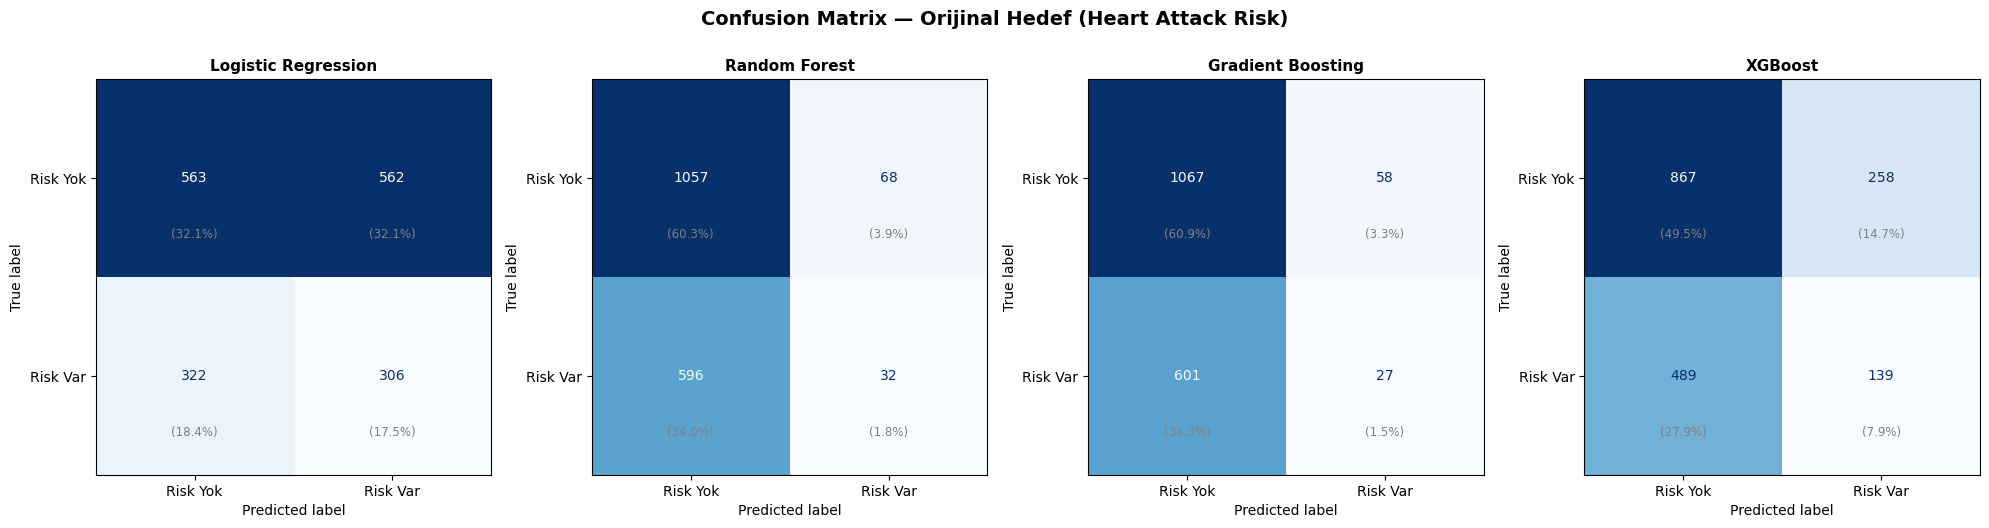

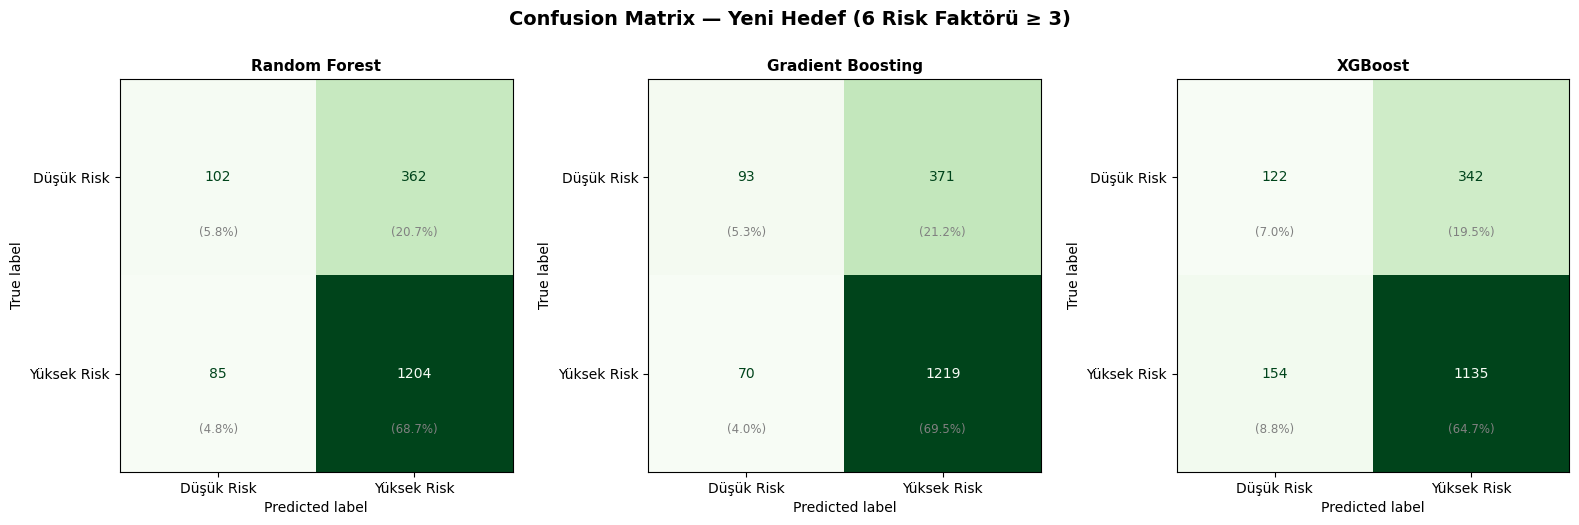

/var/folders/2k/3_2c64td3lb8bz3dz2ykrfkm0000gn/T/ipykernel_1287/924035402.py:66: UserWarning: Glyph 11088 (\N{WHITE MEDIUM STAR}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/opt/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 11088 (\N{WHITE MEDIUM STAR}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


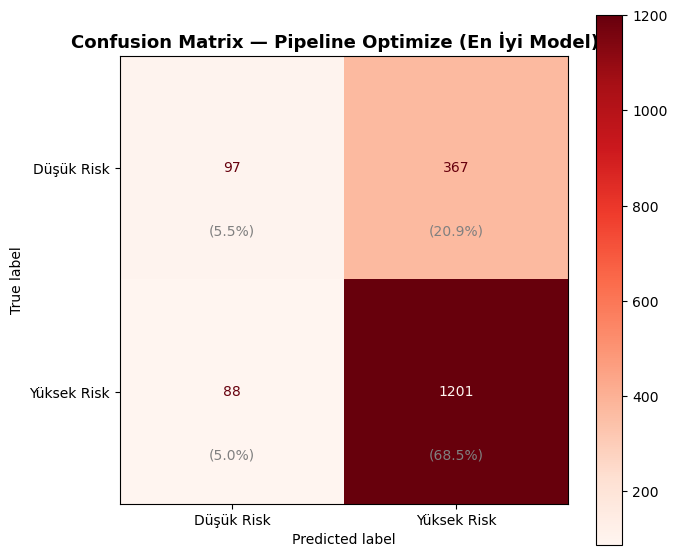

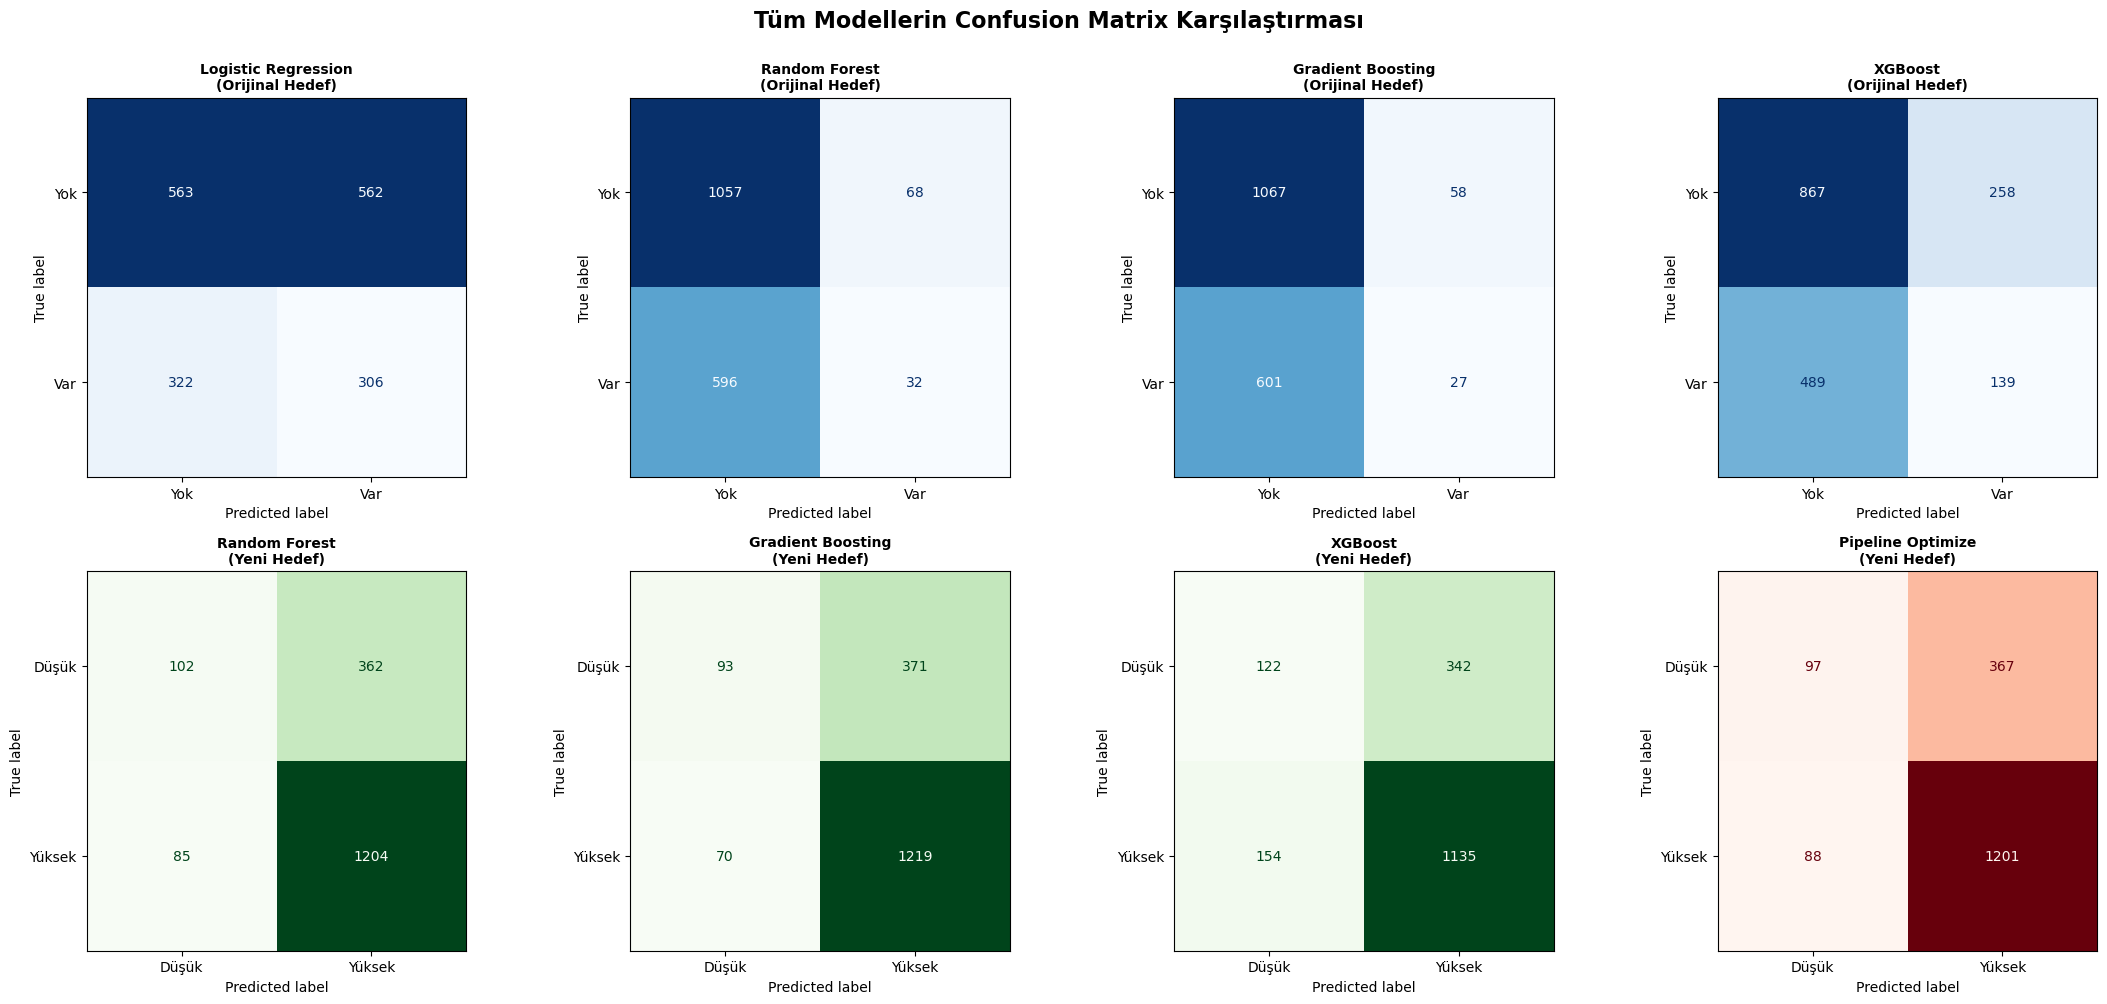

In [10]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# ════════════════════════════════════════════════════════════
# 1) ORİJİNAL HEDEF MODELLERİ — 4 Confusion Matrix
# ════════════════════════════════════════════════════════════
fig1, axes1 = plt.subplots(1, 4, figsize=(20, 5))
fig1.suptitle("Confusion Matrix — Orijinal Hedef (Heart Attack Risk)",
              fontweight="bold", fontsize=14, y=1.02)

for ax, (isim, model) in zip(axes1, modeller_orig.items()):
    y_pred = model.predict(X1_test_sc)
    cm = confusion_matrix(y1_test, y_pred)
    disp = ConfusionMatrixDisplay(cm, display_labels=["Risk Yok","Risk Var"])
    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(isim, fontsize=11, fontweight="bold")
    total = cm.sum()
    for i in range(2):
        for j in range(2):
            ax.text(j, i+0.3, f"({cm[i,j]/total*100:.1f}%)",
                    ha="center", fontsize=8.5, color="gray")

plt.tight_layout()
plt.show()

# ════════════════════════════════════════════════════════════
# 2) YENİ HEDEF MODELLERİ — 3 Confusion Matrix
# ════════════════════════════════════════════════════════════
fig2, axes2 = plt.subplots(1, 3, figsize=(16, 5))
fig2.suptitle("Confusion Matrix — Yeni Hedef (6 Risk Faktörü ≥ 3)",
              fontweight="bold", fontsize=14, y=1.02)

for ax, (isim, model) in zip(axes2, modeller_yeni.items()):
    y_pred = model.predict(X2_test_sc)
    cm = confusion_matrix(y2_test, y_pred)
    disp = ConfusionMatrixDisplay(cm, display_labels=["Düşük Risk","Yüksek Risk"])
    disp.plot(ax=ax, cmap="Greens", colorbar=False)
    ax.set_title(isim, fontsize=11, fontweight="bold")
    total = cm.sum()
    for i in range(2):
        for j in range(2):
            ax.text(j, i+0.3, f"({cm[i,j]/total*100:.1f}%)",
                    ha="center", fontsize=8.5, color="gray")

plt.tight_layout()
plt.show()

# ════════════════════════════════════════════════════════════
# 3) PIPELINE OPTİMİZE MODEL — Tek Confusion Matrix (büyük, vurgulu)
# ════════════════════════════════════════════════════════════
fig3, ax3 = plt.subplots(figsize=(7, 6))
y_pred_opt = search.predict(X2_test_sc)
cm_opt = confusion_matrix(y2_test, y_pred_opt)

disp_opt = ConfusionMatrixDisplay(cm_opt, display_labels=["Düşük Risk","Yüksek Risk"])
disp_opt.plot(ax=ax3, cmap="Reds", colorbar=True)
ax3.set_title("Confusion Matrix — Pipeline Optimize (En İyi Model) ⭐",
              fontweight="bold", fontsize=13)

total_opt = cm_opt.sum()
for i in range(2):
    for j in range(2):
        ax3.text(j, i+0.3, f"({cm_opt[i,j]/total_opt*100:.1f}%)",
                ha="center", fontsize=10, color="gray")

plt.tight_layout()
plt.show()

# ════════════════════════════════════════════════════════════
# 4) HEPSİ TEK GRAFİKTE (8 model, 2x4 grid)
# ════════════════════════════════════════════════════════════
fig4, axes4 = plt.subplots(2, 4, figsize=(22, 10))
fig4.suptitle("Tüm Modellerin Confusion Matrix Karşılaştırması",
              fontweight="bold", fontsize=16, y=1.0)

# Üst satır: orijinal hedef (4 model)
for ax, (isim, model) in zip(axes4[0], modeller_orig.items()):
    y_pred = model.predict(X1_test_sc)
    cm = confusion_matrix(y1_test, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=["Yok","Var"]).plot(
        ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{isim}\n(Orijinal Hedef)", fontsize=10, fontweight="bold")

# Alt satır: yeni hedef (3 model) + pipeline optimize
modeller_alt = list(modeller_yeni.items()) + [("Pipeline Optimize", search)]
for ax, (isim, model) in zip(axes4[1], modeller_alt):
    y_pred = model.predict(X2_test_sc)
    cm = confusion_matrix(y2_test, y_pred)
    cmap = "Reds" if isim == "Pipeline Optimize" else "Greens"
    ConfusionMatrixDisplay(cm, display_labels=["Düşük","Yüksek"]).plot(
        ax=ax, cmap=cmap, colorbar=False)
    ax.set_title(f"{isim}\n(Yeni Hedef)", fontsize=10, fontweight="bold")

# Boş kalan 8. hücreyi gizle (4 model orijinal + 4 model yeni = 8 ama yeni'de 4 var)
axes4[1, 3].axis("off") if len(modeller_alt) < 4 else None

plt.tight_layout()
plt.show()

/var/folders/2k/3_2c64td3lb8bz3dz2ykrfkm0000gn/T/ipykernel_1287/2254095143.py:162: UserWarning: Glyph 11088 (\N{WHITE MEDIUM STAR}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/2k/3_2c64td3lb8bz3dz2ykrfkm0000gn/T/ipykernel_1287/2254095143.py:163: UserWarning: Glyph 11088 (\N{WHITE MEDIUM STAR}) missing from font(s) DejaVu Sans.
  plt.savefig("model_karsilastirma_tablosu.png", dpi=200, bbox_inches="tight", facecolor="#F7F5F0")
/opt/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 11088 (\N{WHITE MEDIUM STAR}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


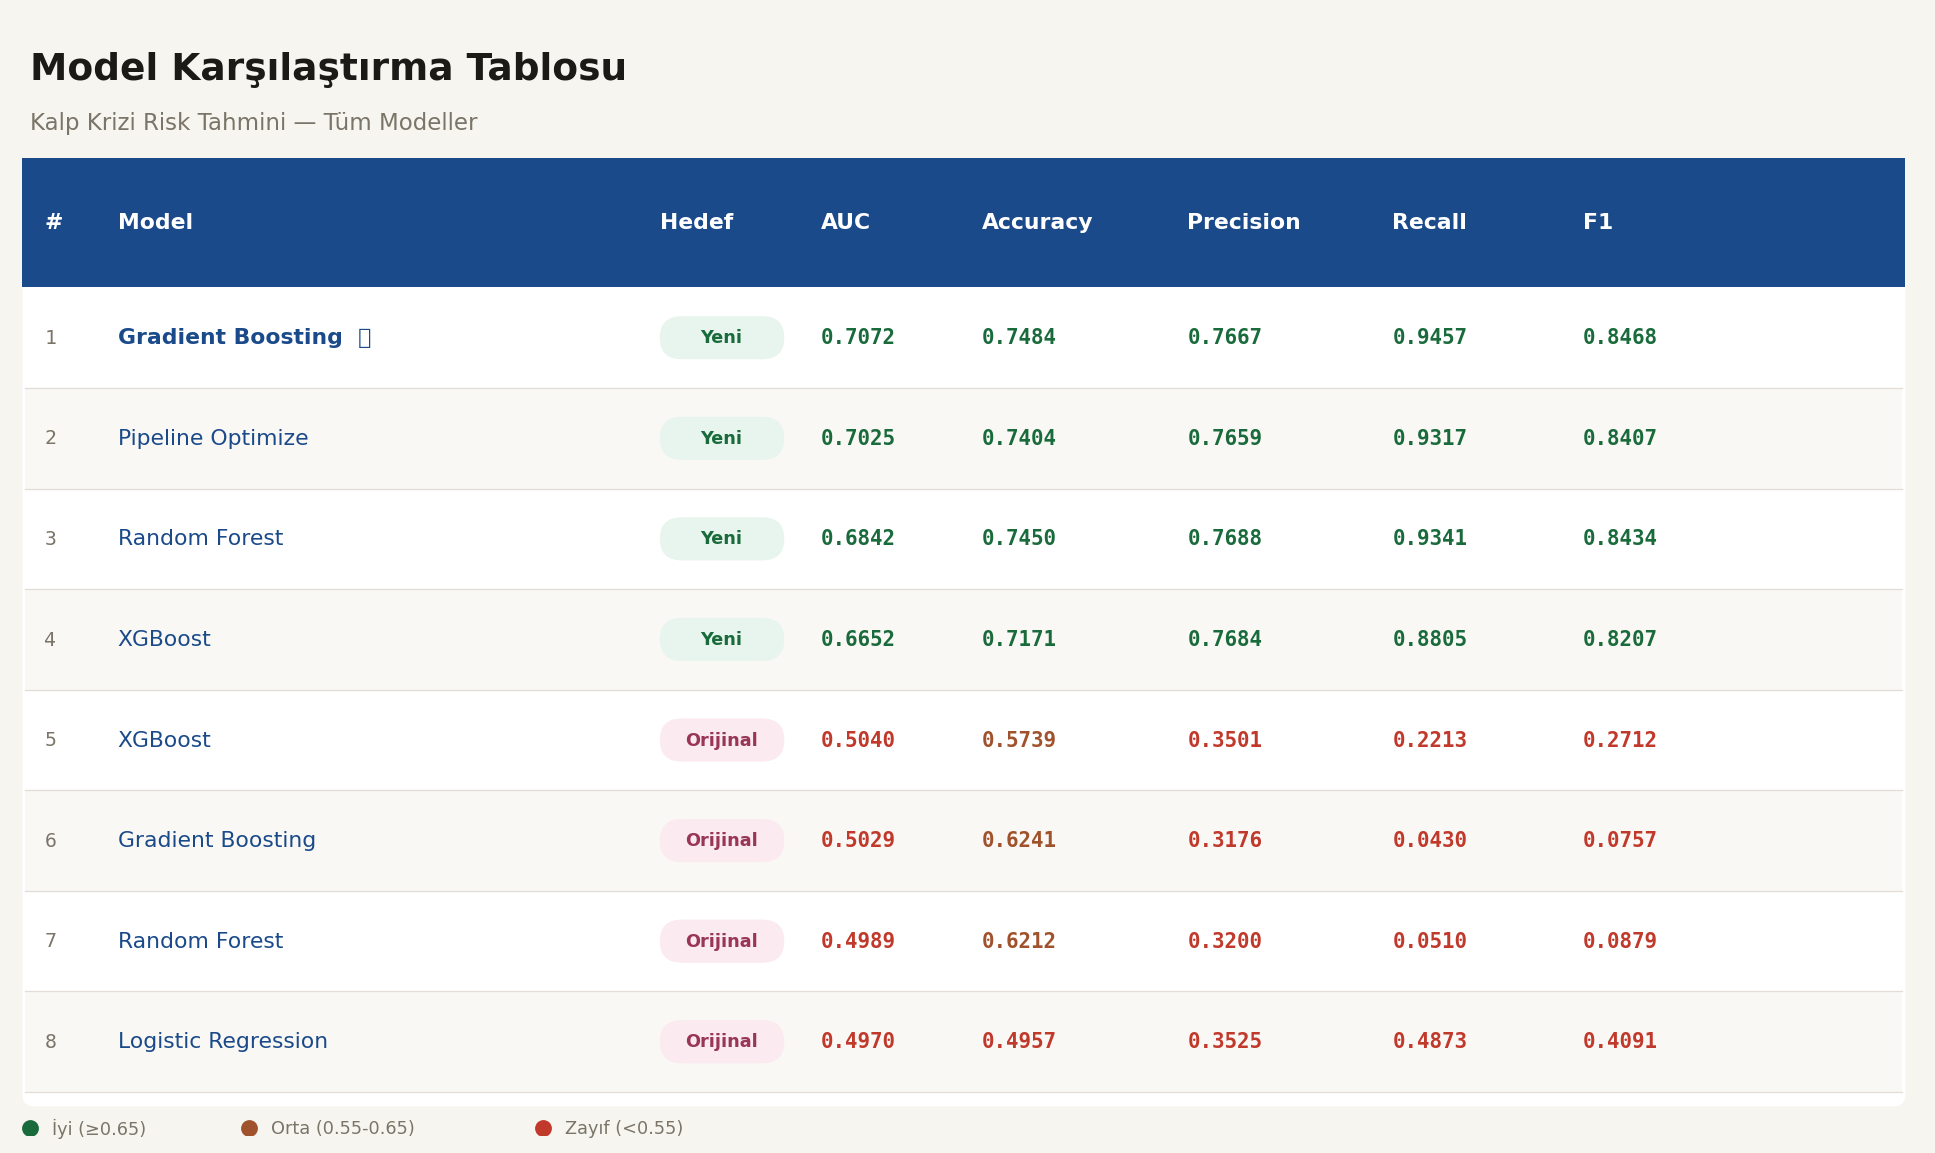

✅ Tablo kaydedildi: model_karsilastirma_tablosu.png


In [11]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from sklearn.metrics import (roc_auc_score, recall_score, precision_score,
                              f1_score, accuracy_score)

# ════════════════════════════════════════════════════════════
# 1) TÜM MODELLERİN METRİKLERİNİ TOPLA
# ════════════════════════════════════════════════════════════
sonuc_listesi = []

# Orijinal hedef modelleri
for isim, model in modeller_orig.items():
    y_pred = model.predict(X1_test_sc)
    y_prob = model.predict_proba(X1_test_sc)[:, 1]
    sonuc_listesi.append({
        "Model": isim,
        "Hedef": "Orijinal",
        "AUC": roc_auc_score(y1_test, y_prob),
        "Accuracy": accuracy_score(y1_test, y_pred),
        "Precision": precision_score(y1_test, y_pred),
        "Recall": recall_score(y1_test, y_pred),
        "F1": f1_score(y1_test, y_pred),
    })

# Yeni hedef modelleri
for isim, model in modeller_yeni.items():
    y_pred = model.predict(X2_test_sc)
    y_prob = model.predict_proba(X2_test_sc)[:, 1]
    sonuc_listesi.append({
        "Model": isim,
        "Hedef": "Yeni",
        "AUC": roc_auc_score(y2_test, y_prob),
        "Accuracy": accuracy_score(y2_test, y_pred),
        "Precision": precision_score(y2_test, y_pred),
        "Recall": recall_score(y2_test, y_pred),
        "F1": f1_score(y2_test, y_pred),
    })

# Pipeline optimize model
y_pred_opt = search.predict(X2_test_sc)
y_prob_opt = search.predict_proba(X2_test_sc)[:, 1]
sonuc_listesi.append({
    "Model": "Pipeline Optimize",
    "Hedef": "Yeni",
    "AUC": roc_auc_score(y2_test, y_prob_opt),
    "Accuracy": accuracy_score(y2_test, y_pred_opt),
    "Precision": precision_score(y2_test, y_pred_opt),
    "Recall": recall_score(y2_test, y_pred_opt),
    "F1": f1_score(y2_test, y_pred_opt),
})

ozet_df = pd.DataFrame(sonuc_listesi).sort_values("AUC", ascending=False).reset_index(drop=True)

# ════════════════════════════════════════════════════════════
# 2) GÖRSEL TABLO OLUŞTUR
# ════════════════════════════════════════════════════════════
n_rows = len(ozet_df)
row_h = 0.7
header_h = 0.9
title_h = 1.0
fig_h = title_h + header_h + n_rows * row_h + 0.3
fig_w = 13

fig, ax = plt.subplots(figsize=(fig_w, fig_h), dpi=150)
ax.set_xlim(0, fig_w)
ax.set_ylim(0, fig_h)
ax.axis("off")
fig.patch.set_facecolor("#F7F5F0")

# Başlık
ax.text(0.1, fig_h - 0.45, "Model Karşılaştırma Tablosu",
        fontsize=18, fontweight="bold", color="#1C1A17")
ax.text(0.1, fig_h - 0.8, "Kalp Krizi Risk Tahmini — Tüm Modeller",
        fontsize=11, color="#7A7568")

# Sütun pozisyonları
headers = ["#", "Model", "Hedef", "AUC", "Accuracy", "Precision", "Recall", "F1"]
col_x   = [0.1, 0.6, 4.3, 5.4, 6.5, 7.9, 9.3, 10.6]
col_w   = [0.5, 3.7, 1.1, 1.1, 1.4, 1.4, 1.3, 1.4]

table_top = fig_h - title_h
table_bottom = 0.2
table_height = table_top - table_bottom

# Dış çerçeve
bg = FancyBboxPatch((0.05, table_bottom), fig_w-0.15, table_height,
                     boxstyle="round,pad=0,rounding_size=0.08",
                     linewidth=0, facecolor="white", zorder=2)
ax.add_patch(bg)

# Header
header_rect = plt.Rectangle((0.05, table_top - header_h), fig_w-0.15, header_h,
                             linewidth=0, facecolor="#1A4A8A", zorder=3)
ax.add_patch(header_rect)
for cx, htext in zip(col_x, headers):
    ax.text(cx + 0.1, table_top - header_h/2, htext, fontsize=10.5,
            fontweight="bold", color="white", va="center", zorder=4)

# Renk skalası fonksiyonu (AUC bazlı yeşil-kırmızı gradient)
def metric_color(val, metric):
    if val >= 0.65:
        return "#1A6B3C"
    elif val >= 0.55:
        return "#A0522D"
    else:
        return "#C0392B"

y = table_top - header_h
for i, row in ozet_df.iterrows():
    row_top = y
    row_bottom = y - row_h
    mid_y = row_top - row_h/2

    if i % 2 == 1:
        ax.add_patch(plt.Rectangle((0.07, row_bottom), fig_w-0.19, row_h,
                                    linewidth=0, facecolor="#FAF8F4", zorder=2))

    ax.plot([0.07, fig_w-0.12], [row_bottom, row_bottom],
            color="#E2DDD6", linewidth=0.6, zorder=3)

    # # sırası
    ax.text(col_x[0]+0.1, mid_y, str(i+1), fontsize=9.5, color="#7A7568",
            va="center", family="monospace", zorder=4)

    # Model adı (en iyi model için yıldız)
    model_label = row["Model"]
    if i == 0:
        model_label += "  ⭐"
    ax.text(col_x[1]+0.1, mid_y, model_label, fontsize=10.5, color="#1A4A8A",
            va="center", fontweight="bold" if i==0 else "normal", zorder=4)

    # Hedef pill
    hedef_bg = "#E8F5EE" if row["Hedef"]=="Yeni" else "#FBEAF0"
    hedef_fg = "#1A6B3C" if row["Hedef"]=="Yeni" else "#993556"
    ax.add_patch(FancyBboxPatch((col_x[2]+0.1, mid_y-0.15), 0.85, 0.3,
                 boxstyle="round,pad=0,rounding_size=0.15",
                 linewidth=0, facecolor=hedef_bg, zorder=4))
    ax.text(col_x[2]+0.52, mid_y, row["Hedef"], fontsize=8.5, color=hedef_fg,
            va="center", ha="center", fontweight="bold", zorder=5)

    # Metrik değerleri (renkli)
    metrics = [("AUC", row["AUC"]), ("Accuracy", row["Accuracy"]),
               ("Precision", row["Precision"]), ("Recall", row["Recall"]),
               ("F1", row["F1"])]
    for (mname, mval), cx in zip(metrics, col_x[3:]):
        color = metric_color(mval, mname)
        ax.text(cx+0.1, mid_y, f"{mval:.4f}", fontsize=10, color=color,
                va="center", fontweight="bold", family="monospace", zorder=4)

    y = row_bottom

# Renk açıklaması (legend)
legend_y = 0.05
ax.scatter([0.1], [legend_y], s=50, color="#1A6B3C", zorder=5)
ax.text(0.25, legend_y, "İyi (≥0.65)", fontsize=8.5, color="#7A7568", va="center")
ax.scatter([1.6], [legend_y], s=50, color="#A0522D", zorder=5)
ax.text(1.75, legend_y, "Orta (0.55-0.65)", fontsize=8.5, color="#7A7568", va="center")
ax.scatter([3.6], [legend_y], s=50, color="#C0392B", zorder=5)
ax.text(3.75, legend_y, "Zayıf (<0.55)", fontsize=8.5, color="#7A7568", va="center")

plt.tight_layout()
plt.savefig("model_karsilastirma_tablosu.png", dpi=200, bbox_inches="tight", facecolor="#F7F5F0")
plt.show()
print("✅ Tablo kaydedildi: model_karsilastirma_tablosu.png")

─── TÜM DENENEN KOMBİNASYONLAR ───────────────────
    n_estimators  max_depth  learning_rate  subsample  CV_AUC     Std  Sıra
0            200          4           0.10        0.8  0.6998  0.0143     1
1            300          2           0.10        1.0  0.6985  0.0150     2
2            200          4           0.05        0.8  0.6977  0.0149     3
3            100          4           0.10        0.7  0.6970  0.0123     4
4            200          3           0.10        0.8  0.6969  0.0140     5
5            100          4           0.05        0.7  0.6967  0.0108     6
6            200          3           0.05        0.7  0.6957  0.0138     7
7            300          2           0.10        0.7  0.6950  0.0179     8
8            300          2           0.20        0.8  0.6934  0.0119     9
9            200          2           0.10        0.7  0.6928  0.0159    10
10           200          3           0.20        1.0  0.6922  0.0129    11
11           200          2          

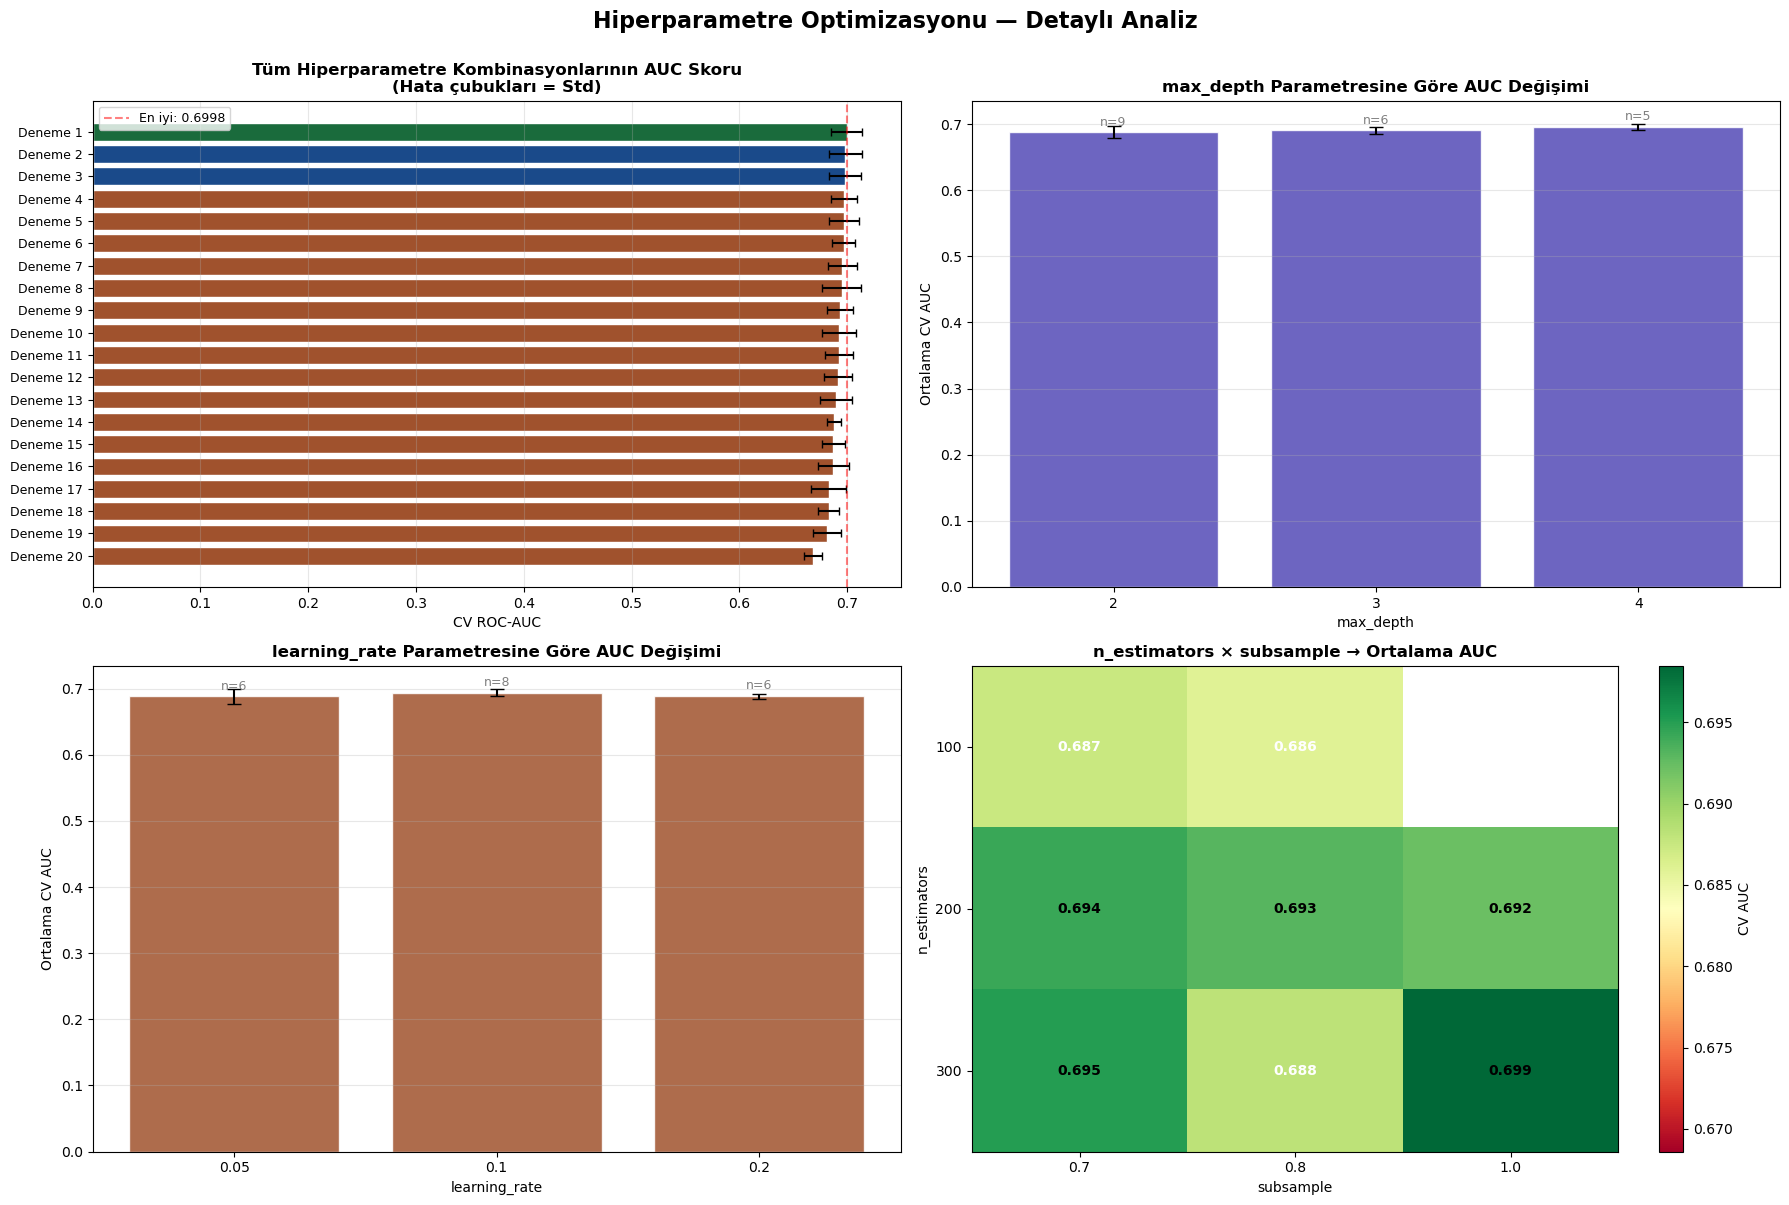


           🏆 EN İYİ HİPERPARAMETRELER
  model__subsample               : 0.8
  model__n_estimators            : 200
  model__max_depth               : 4
  model__learning_rate           : 0.1

  CV ROC-AUC (en iyi)        : 0.6998
  Test ROC-AUC               : 0.7025


In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# ════════════════════════════════════════════════════════════
# 1) TÜM DENENEN HİPERPARAMETRE KOMBİNASYONLARINI ÇIKAR
# ════════════════════════════════════════════════════════════
cv_results = pd.DataFrame(search.cv_results_)

# Sadece önemli sütunları al ve düzenle
sonuc_tablo = cv_results[[
    "param_model__n_estimators",
    "param_model__max_depth",
    "param_model__learning_rate",
    "param_model__subsample",
    "mean_test_score",
    "std_test_score",
    "rank_test_score"
]].copy()

sonuc_tablo.columns = ["n_estimators", "max_depth", "learning_rate",
                       "subsample", "CV_AUC", "Std", "Sıra"]
sonuc_tablo = sonuc_tablo.sort_values("Sıra").reset_index(drop=True)
sonuc_tablo["CV_AUC"] = sonuc_tablo["CV_AUC"].round(4)
sonuc_tablo["Std"] = sonuc_tablo["Std"].round(4)

print("─── TÜM DENENEN KOMBİNASYONLAR ───────────────────")
print(sonuc_tablo.to_string(index=True))

# ════════════════════════════════════════════════════════════
# 2) GÖRSEL: Her Kombinasyonun AUC Skoru (Bar Chart)
# ════════════════════════════════════════════════════════════
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# ── Panel 1: Tüm kombinasyonların sıralı AUC skoru ─────────
ax1 = axes[0, 0]
colors_bar = ["#1A6B3C" if i == 0 else "#1A4A8A" if i < 3 else "#A0522D"
              for i in range(len(sonuc_tablo))]
bars = ax1.barh(range(len(sonuc_tablo)), sonuc_tablo["CV_AUC"],
                xerr=sonuc_tablo["Std"], color=colors_bar,
                edgecolor="white", capsize=3)
ax1.set_yticks(range(len(sonuc_tablo)))
ax1.set_yticklabels([f"Deneme {i+1}" for i in range(len(sonuc_tablo))], fontsize=9)
ax1.invert_yaxis()
ax1.axvline(sonuc_tablo["CV_AUC"].max(), color="red", linestyle="--",
            alpha=0.5, label=f"En iyi: {sonuc_tablo['CV_AUC'].max():.4f}")
ax1.set_xlabel("CV ROC-AUC")
ax1.set_title("Tüm Hiperparametre Kombinasyonlarının AUC Skoru\n(Hata çubukları = Std)",
              fontweight="bold", fontsize=12)
ax1.legend(fontsize=9)
ax1.grid(alpha=0.3, axis="x")

# ── Panel 2: max_depth'e göre AUC değişimi ─────────────────
ax2 = axes[0, 1]
depth_groups = sonuc_tablo.groupby("max_depth")["CV_AUC"].agg(["mean", "std", "count"])
ax2.bar(depth_groups.index.astype(str), depth_groups["mean"],
        yerr=depth_groups["std"], color="#534AB7", edgecolor="white",
        capsize=5, alpha=0.85)
for i, (idx, row) in enumerate(depth_groups.iterrows()):
    ax2.text(i, row["mean"]+0.01, f"n={int(row['count'])}",
             ha="center", fontsize=9, color="gray")
ax2.set_xlabel("max_depth")
ax2.set_ylabel("Ortalama CV AUC")
ax2.set_title("max_depth Parametresine Göre AUC Değişimi",
              fontweight="bold", fontsize=12)
ax2.grid(alpha=0.3, axis="y")

# ── Panel 3: learning_rate'e göre AUC değişimi ──────────────
ax3 = axes[1, 0]
lr_groups = sonuc_tablo.groupby("learning_rate")["CV_AUC"].agg(["mean", "std", "count"])
ax3.bar(lr_groups.index.astype(str), lr_groups["mean"],
        yerr=lr_groups["std"], color="#A0522D", edgecolor="white",
        capsize=5, alpha=0.85)
for i, (idx, row) in enumerate(lr_groups.iterrows()):
    ax3.text(i, row["mean"]+0.01, f"n={int(row['count'])}",
             ha="center", fontsize=9, color="gray")
ax3.set_xlabel("learning_rate")
ax3.set_ylabel("Ortalama CV AUC")
ax3.set_title("learning_rate Parametresine Göre AUC Değişimi",
              fontweight="bold", fontsize=12)
ax3.grid(alpha=0.3, axis="y")

# ── Panel 4: n_estimators ve subsample birlikte (heatmap) ──
ax4 = axes[1, 1]
pivot = sonuc_tablo.pivot_table(
    index="n_estimators", columns="subsample",
    values="CV_AUC", aggfunc="mean"
)
im = ax4.imshow(pivot.values, cmap="RdYlGn", aspect="auto", vmin=sonuc_tablo["CV_AUC"].min())
ax4.set_xticks(range(len(pivot.columns)))
ax4.set_xticklabels(pivot.columns)
ax4.set_yticks(range(len(pivot.index)))
ax4.set_yticklabels(pivot.index)
ax4.set_xlabel("subsample")
ax4.set_ylabel("n_estimators")
ax4.set_title("n_estimators × subsample → Ortalama AUC",
              fontweight="bold", fontsize=12)

for i in range(len(pivot.index)):
    for j in range(len(pivot.columns)):
        val = pivot.values[i, j]
        if not np.isnan(val):
            ax4.text(j, i, f"{val:.3f}", ha="center", va="center",
                     fontsize=10, fontweight="bold",
                     color="white" if val < pivot.values[~np.isnan(pivot.values)].mean() else "black")
plt.colorbar(im, ax=ax4, label="CV AUC")

plt.suptitle("Hiperparametre Optimizasyonu — Detaylı Analiz",
             fontsize=16, fontweight="bold", y=1.0)
plt.tight_layout()
plt.savefig("hiperparametre_analizi.png", dpi=150, bbox_inches="tight", facecolor="white")
plt.show()

# ════════════════════════════════════════════════════════════
# 3) EN İYİ PARAMETRELER ÖZET KARTI
# ════════════════════════════════════════════════════════════
print("\n" + "="*55)
print("           🏆 EN İYİ HİPERPARAMETRELER")
print("="*55)
for param, val in search.best_params_.items():
    print(f"  {param:30} : {val}")
print(f"\n  CV ROC-AUC (en iyi)        : {round(search.best_score_, 4)}")
print(f"  Test ROC-AUC               : {round(roc_auc_score(y2_test, search.predict_proba(X2_test_sc)[:,1]), 4)}")
print("="*55)

─── ÖZELLİK ÖNEM TABLOSU (Tüm Özellikler) ────────
                            Özellik  Önem Skoru  Yüzde
0                Sedentary_x_Stress      0.1429  14.29
1                              Diet      0.1093  10.93
2   Physical Activity Days Per Week      0.0997   9.97
3                               Sex      0.0956   9.56
4                         Continent      0.0881   8.81
5           Sedentary Hours Per Day      0.0860   8.60
6                               Age      0.0639   6.39
7                      BMI_Category      0.0305   3.05
8                            Income      0.0243   2.43
9                        Heart Rate      0.0212   2.12
10          Exercise Hours Per Week      0.0189   1.89
11                          Country      0.0187   1.87
12                              BMI      0.0176   1.76
13                Age_x_Cholesterol      0.0172   1.72
14                    Triglycerides      0.0171   1.71
15                          Obesity      0.0166   1.66
16            

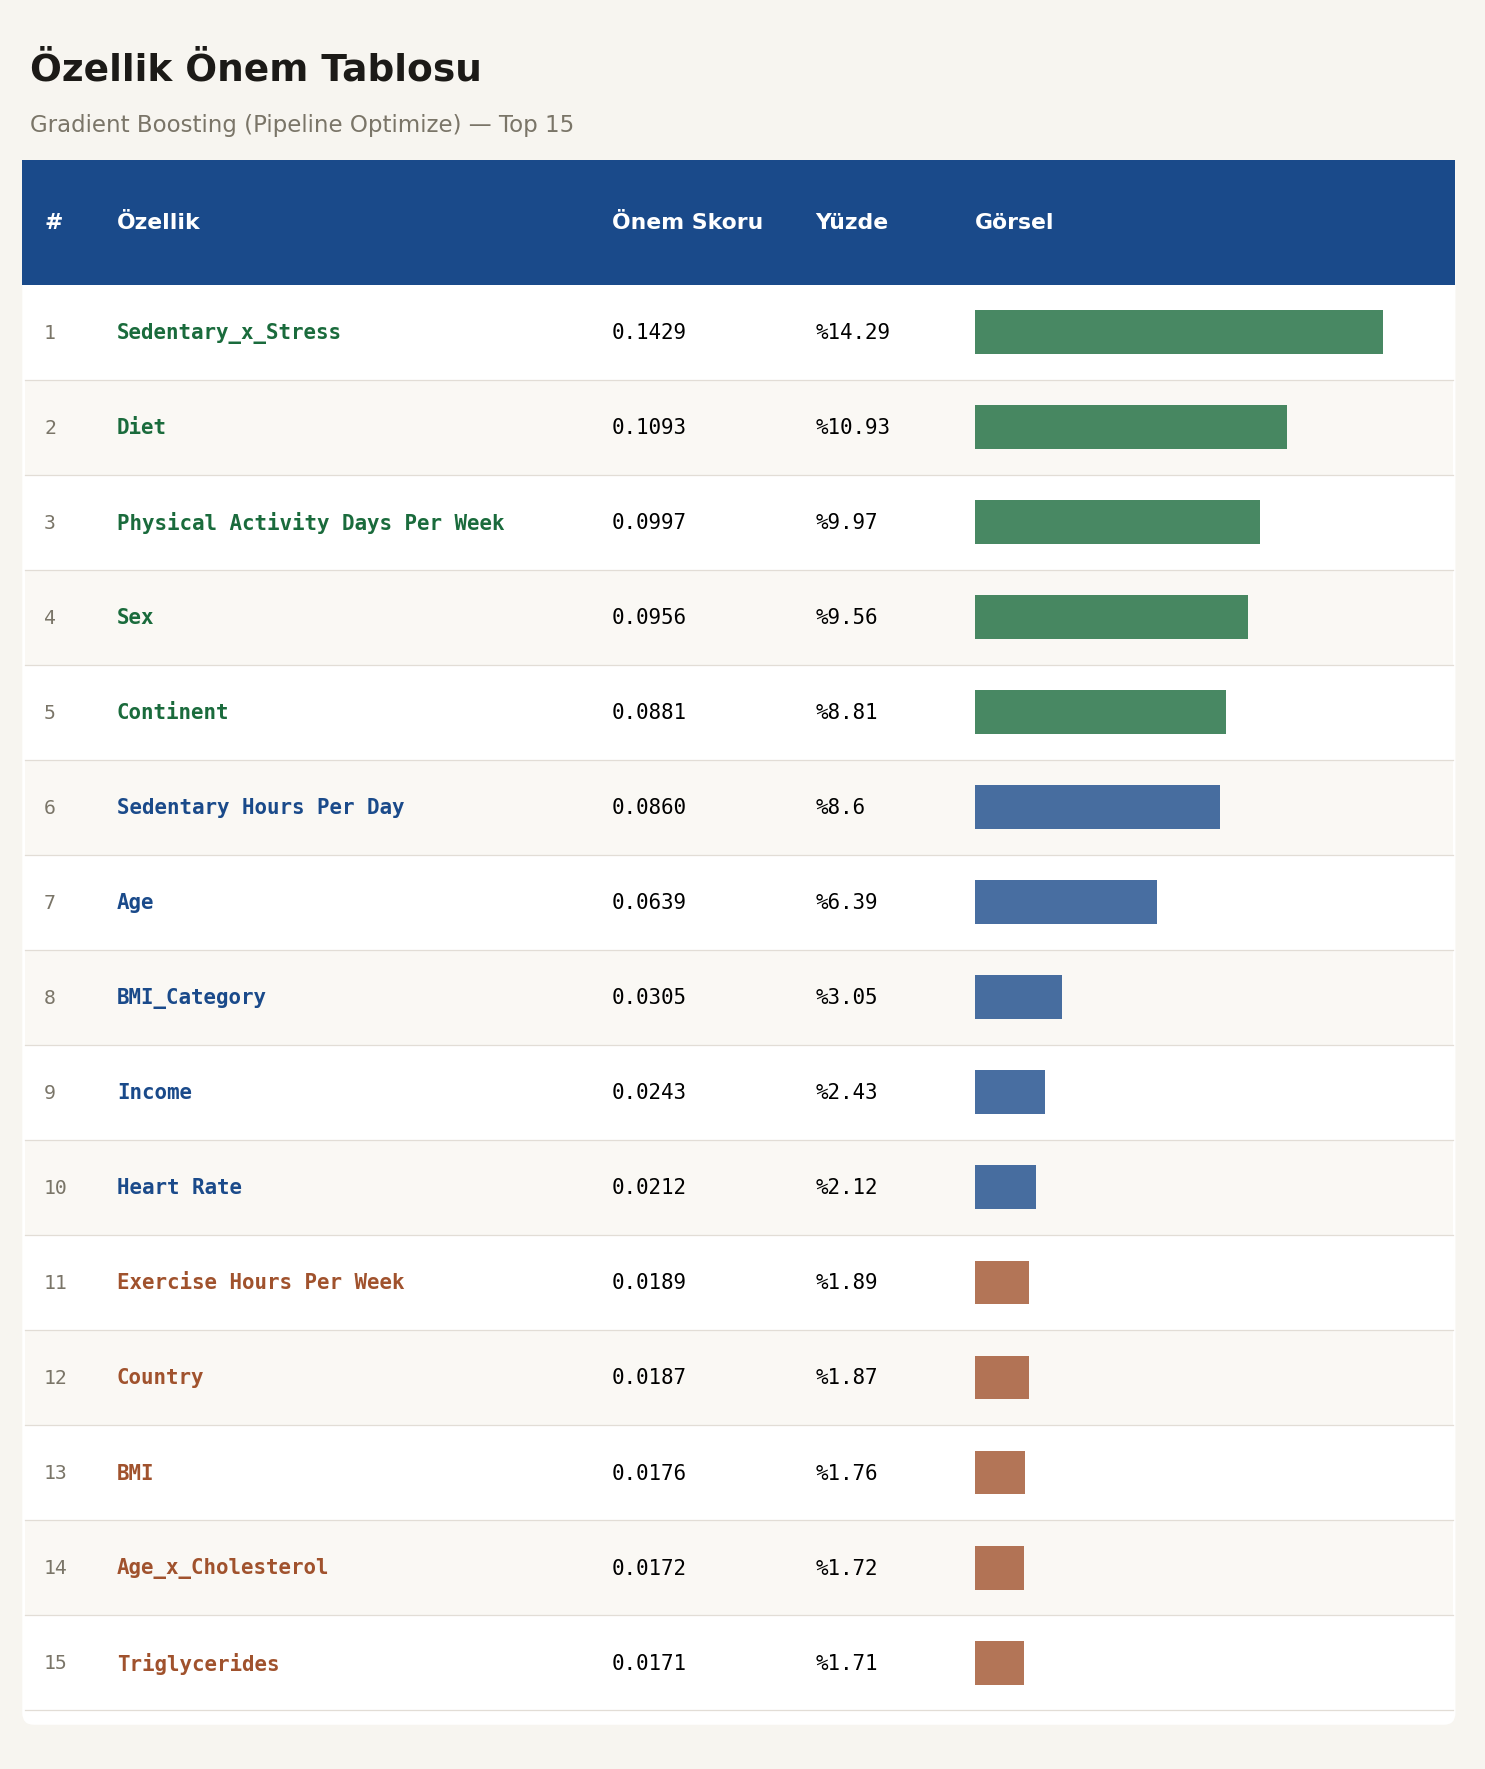

✅ Görsel kaydedildi: ozellik_onem_tablosu.png


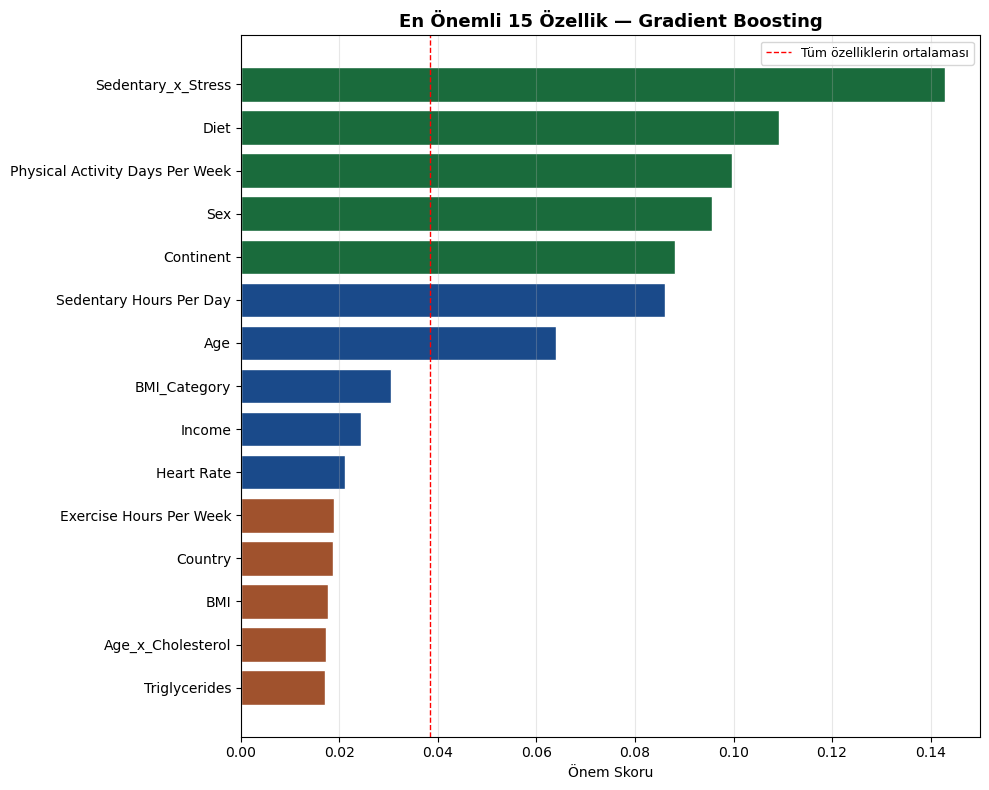

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

# ════════════════════════════════════════════════════════════
# 1) ÖZELLİK ÖNEMLERİNİ ÇIKAR
# ════════════════════════════════════════════════════════════
best_gb = search.best_estimator_.named_steps["model"]

onem_df = pd.DataFrame({
    "Özellik": X2_test_sc.columns,
    "Önem Skoru": best_gb.feature_importances_
}).sort_values("Önem Skoru", ascending=False).reset_index(drop=True)

onem_df["Yüzde"] = (onem_df["Önem Skoru"] / onem_df["Önem Skoru"].sum() * 100).round(2)
onem_df["Önem Skoru"] = onem_df["Önem Skoru"].round(4)

print("─── ÖZELLİK ÖNEM TABLOSU (Tüm Özellikler) ────────")
print(onem_df.to_string(index=True))

# CSV olarak kaydet
onem_df.to_csv("ozellik_onem_tablosu.csv", index=False, encoding="utf-8-sig")
print("\n✅ CSV kaydedildi: ozellik_onem_tablosu.csv")

# ════════════════════════════════════════════════════════════
# 2) GÖRSEL TABLO — Top 15 Özellik
# ════════════════════════════════════════════════════════════
top15 = onem_df.head(15)

n_rows = len(top15)
row_h = 0.65
header_h = 0.85
title_h = 1.0
fig_h = title_h + header_h + n_rows * row_h + 0.3
fig_w = 10

fig, ax = plt.subplots(figsize=(fig_w, fig_h), dpi=150)
ax.set_xlim(0, fig_w)
ax.set_ylim(0, fig_h)
ax.axis("off")
fig.patch.set_facecolor("#F7F5F0")

ax.text(0.1, fig_h - 0.45, "Özellik Önem Tablosu", fontsize=18,
        fontweight="bold", color="#1C1A17")
ax.text(0.1, fig_h - 0.8, "Gradient Boosting (Pipeline Optimize) — Top 15",
        fontsize=11, color="#7A7568")

headers = ["#", "Özellik", "Önem Skoru", "Yüzde", "Görsel"]
col_x = [0.1, 0.6, 4.0, 5.4, 6.5]

table_top = fig_h - title_h
table_bottom = 0.2
table_height = table_top - table_bottom

bg = FancyBboxPatch((0.05, table_bottom), fig_w-0.15, table_height,
                     boxstyle="round,pad=0,rounding_size=0.08",
                     linewidth=0, facecolor="white", zorder=2)
ax.add_patch(bg)

header_rect = plt.Rectangle((0.05, table_top - header_h), fig_w-0.15, header_h,
                             linewidth=0, facecolor="#1A4A8A", zorder=3)
ax.add_patch(header_rect)
for cx, htext in zip(col_x, headers):
    ax.text(cx + 0.1, table_top - header_h/2, htext, fontsize=10.5,
            fontweight="bold", color="white", va="center", zorder=4)

max_skor = top15["Önem Skoru"].max()
y = table_top - header_h

for i, row in top15.iterrows():
    row_top = y
    row_bottom = y - row_h
    mid_y = row_top - row_h/2

    if i % 2 == 1:
        ax.add_patch(plt.Rectangle((0.07, row_bottom), fig_w-0.19, row_h,
                                    linewidth=0, facecolor="#FAF8F4", zorder=2))

    ax.plot([0.07, fig_w-0.12], [row_bottom, row_bottom],
            color="#E2DDD6", linewidth=0.6, zorder=3)

    renk = "#1A6B3C" if i < 5 else "#1A4A8A" if i < 10 else "#A0522D"

    ax.text(col_x[0]+0.1, mid_y, str(i+1), fontsize=9.5, color="#7A7568",
            va="center", family="monospace", zorder=4)
    ax.text(col_x[1]+0.1, mid_y, row["Özellik"], fontsize=10, color=renk,
            va="center", fontweight="bold", family="monospace", zorder=4)
    ax.text(col_x[2]+0.1, mid_y, f"{row['Önem Skoru']:.4f}", fontsize=10,
            va="center", family="monospace", zorder=4)
    ax.text(col_x[3]+0.1, mid_y, f"%{row['Yüzde']}", fontsize=10,
            va="center", family="monospace", zorder=4)

    # Mini bar görseli
    bar_w = (row["Önem Skoru"] / max_skor) * 2.8
    ax.add_patch(plt.Rectangle((col_x[4]+0.1, mid_y-0.15), bar_w, 0.3,
                                linewidth=0, facecolor=renk, alpha=0.8, zorder=4))

    y = row_bottom

plt.tight_layout()
plt.savefig("ozellik_onem_tablosu.png", dpi=200, bbox_inches="tight", facecolor="#F7F5F0")
plt.show()
print("✅ Görsel kaydedildi: ozellik_onem_tablosu.png")

# ════════════════════════════════════════════════════════════
# 3) KLASİK BAR CHART (alternatif görsel)
# ════════════════════════════════════════════════════════════
fig2, ax2 = plt.subplots(figsize=(10, 8))
renkler = ["#1A6B3C" if i<5 else "#1A4A8A" if i<10 else "#A0522D"
           for i in range(len(top15))]

ax2.barh(top15["Özellik"][::-1], top15["Önem Skoru"][::-1],
         color=renkler[::-1], edgecolor="white")
ax2.axvline(onem_df["Önem Skoru"].mean(), color="red", linestyle="--",
            linewidth=1, label="Tüm özelliklerin ortalaması")
ax2.set_xlabel("Önem Skoru")
ax2.set_title("En Önemli 15 Özellik — Gradient Boosting",
              fontweight="bold", fontsize=13)
ax2.legend(fontsize=9)
ax2.grid(alpha=0.3, axis="x")

plt.tight_layout()
plt.savefig("ozellik_onem_bar.png", dpi=150, bbox_inches="tight", facecolor="white")
plt.show()